# Phase 5: Injury analysis (pattern evaluation)

**Question:** how did playing styles evolve between 2014/15 and 2025/26, and how did injuries (frequency, days lost,
body area) change with them, across seasons and leagues?

**Unit:** the **player-club-season** (Phase 2 membership), carrying its team's **attacking style**, **defensive
style**, their combination (Phase 4) and its **formation** (back three: ≥ 50% of minutes). Injuries last > 7 days.

**Methods** (descriptive, as the course allows):
- **Rates:** injuries per player-season, per 1,000 minutes, days lost per player-season, share severe (> 28 days).
- **League-adjusted rate ratio (RR):** observed injuries ÷ expected at the league's 12-season average (indirect
  standardisation), because Transfermarkt records injuries at very different rates per league. A stricter version
  uses league × age band × position.
- **95% CIs:** bootstrap over **team-seasons** (players of one squad are not independent), 1,000 resamples, seed 42.
- **Tests:** chi-square (observed vs expected; body-area mix with Cramér's V). Body-area patterns are reported only
  when they hold **within leagues** (labelling differs a lot between leagues).
- **Evolution:** eras 2014–18, 2018–22, 2022–26; trend shapes; style transitions; Kitagawa decomposition of injury
  trends into the style mix and within-style change.

**Steps**
1. Player-season table
2. Rate and bootstrap helpers; league baselines
3. Injuries by attacking style, defensive style, combination and formation
4. Body areas by style (within leagues)
5. Seasons: injury trend and style shares over time
6. Leagues: style effects within each league
7. Age and position: is it the squad mix?
8. Team strength and workload
9. Fitness absences (secondary outcome)
10. Sensitivity checks
11. Style cards: what each style looks like on the pitch
12. How the ways of attacking and defending changed, and in what shape
13. How teams move between styles
14. Style mix and injuries per era
15. How much of the injury trend comes from styles changing (decomposition)
16. Style dimensions vs injury outcomes across league-seasons
17. One story per league
18. Making results clearer without overfitting: shrinkage, rolling trends, FDR, breakdowns
19. Report

**Inputs:** `data/02_injuries/`, `data/03_features/`, `data/04_clusters/`, `tm_squads`, `us_team_matches`.
**Outputs:** `data/05_injury_analysis/`, `reports/05_injury_analysis.md`, `reports/figures/05_*.png`.

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2, chi2_contingency

sys.path.insert(0, str(Path.cwd().parent))  # project root, for the analysis package
from analysis.config import DATA_DIR, FIGURES_DIR, REPORTS_DIR, phase_dir
from analysis.load import league_from_understat, read_table
from analysis.report import md_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 160)

PHASE = "05_injury_analysis"
OUT_DIR = phase_dir(PHASE)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
N_BOOT = 1000
AGE_BANDS = [0, 21, 25, 29, 99]  # ≤ 21, 22–25, 26–29, 30+ (age on 1 January of the season)
AGE_LABELS = ["≤21", "22–25", "26–29", "30+"]
COVID_SEASONS = ["2019-20", "2020-21"]
LEAGUES = ["Premier League", "La Liga", "Serie A", "Bundesliga", "Ligue 1"]
ATTACK = ["Positional possession", "Build-up into the box", "Counter-attack", "Direct play"]
DEFENCE = ["High press, high line", "Compact mid-block", "Aggressive duel press", "Low block"]
FORMATION = ["back three", "back four"]
ERAS = {range(2014, 2018): "2014–18", range(2018, 2022): "2018–22", range(2022, 2026): "2022–26"}
ERA_ORDER = list(ERAS.values())
RARE = "rare combination"

# Chart palette: validated reference palette (dataviz skill), categorical slots in fixed order.
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
})


def save(fig, name: str) -> str:
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
    return name


def era_of(season: int) -> str:
    return next(label for years, label in ERAS.items() if season in years)

## Step 1. Player-season table

One row per player-club-season with league, season, club, the team's attacking and defensive style and their
combination, formation, strength (points per match), workload (Phase 3 exposure features), the player's age band and
position, minutes in all competitions, and his injuries there that season (count, days lost, severe, surgery, by body
area), plus mild injuries (4–7 days) and fitness absences.

In [2]:
members = pd.read_parquet(DATA_DIR / "02_injuries" / "player_club_seasons.parquet")
injuries = pd.read_parquet(DATA_DIR / "02_injuries" / "injuries_clean.parquet")
mild = pd.read_parquet(DATA_DIR / "02_injuries" / "injuries_mild.parquet")
non_inj = pd.read_parquet(DATA_DIR / "02_injuries" / "non_injuries.parquet")
clusters = pd.read_parquet(DATA_DIR / "04_clusters" / "team_season_clusters.parquet").rename(columns={"tm_club_id": "club_id"})
features = pd.read_parquet(DATA_DIR / "03_features" / "team_season_features.parquet").rename(columns={"tm_club_id": "club_id"})
style_dims = pd.read_parquet(DATA_DIR / "03_features" / "style_dimensions.parquet").rename(columns={"tm_club_id": "club_id"})
roles = pd.read_csv(DATA_DIR / "03_features" / "feature_roles.csv")
EXPOSURE = roles[(roles.role == "exposure") & (roles.status == "kept")].feature.tolist()
DIMS = {ph: [c for c in style_dims.columns if c.startswith(f"{ph}_")] for ph in ["attack", "defence"]}

clusters["formation"] = np.where(clusters.back_three, "back three", "back four")
clusters["style_group"] = np.where(clusters.rare_style, RARE, clusters["style"])
clusters["era"] = clusters.season.map(era_of)
COMBOS = (clusters[~clusters.rare_style].drop_duplicates("style")
          .assign(a=lambda d: d.attack_style.map(ATTACK.index), d=lambda d: d.defence_style.map(DEFENCE.index))
          .sort_values(["a", "d"])["style"].tolist())

um = read_table("us_team_matches")
points = (um.assign(league=um.league.map(league_from_understat), season=um.season.astype(int), pts=um.pts.astype(float))
          .groupby(["league", "season", "team_id"]).pts.mean().rename("points_pm").reset_index().rename(columns={"team_id": "us_team_id"}))
keys = pd.read_csv(DATA_DIR / "01_entities" / "team_seasons.csv", dtype={"tm_club_id": str, "us_team_id": str}).rename(columns={"tm_club_id": "club_id"})
team = (clusters.merge(keys[["league", "season", "club_id", "us_team_id"]], on=["league", "season", "club_id"])
        .merge(points, on=["league", "season", "us_team_id"])
        .merge(features[["league", "season", "club_id"] + EXPOSURE], on=["league", "season", "club_id"])
        .merge(style_dims[["season", "club_id"] + DIMS["attack"] + DIMS["defence"]], on=["season", "club_id"]))
team["strength"] = pd.qcut(team.points_pm, 3, labels=["weaker third", "middle third", "stronger third"])
assert len(team) == 1170

sq = read_table("tm_squads")
player = sq[["playerId", "position_group", "date_of_birth"]].replace("", np.nan).groupby("playerId").first()
TEAM_COLS = ["league", "season", "club_id", "attack_style", "defence_style", "style", "style_group", "rare_style", "formation",
             "back_three_share", "era", "points_pm", "strength"] + EXPOSURE
ps = members.merge(team[TEAM_COLS], on=["league", "season", "club_id"], how="left").join(player, on="playerId")
dob = pd.to_datetime(ps.date_of_birth, errors="coerce")
ps["age"] = ((pd.to_datetime((ps.season + 1).astype(str) + "-01-01") - dob).dt.days / 365.25).round(1)
ps["age_band"] = pd.cut(ps.age, AGE_BANDS, labels=AGE_LABELS)
ps["position"] = ps.position_group.str.title()

KEY = ["playerId", "club_id", "season"]
inj = injuries.assign(severe=injuries.severity.str.startswith("severe"), surgery=injuries.surgery.astype(bool))
agg = inj.groupby(KEY).agg(injuries=("days", "size"), days_lost=("days", "sum"), severe=("severe", "sum"), surgeries=("surgery", "sum"))
areas = pd.crosstab([inj.playerId, inj.club_id, inj.season], inj.body_area).add_prefix("area: ")
mild_n = mild.groupby(KEY).size().rename("mild_injuries")
fit_n = non_inj[non_inj.non_injury_reason == "fitness"].groupby(KEY).size().rename("fitness_absences")
ps = ps.join(agg, on=KEY).join(areas, on=KEY).join(mild_n, on=KEY).join(fit_n, on=KEY)
count_cols = ["injuries", "days_lost", "severe", "surgeries", "mild_injuries", "fitness_absences"] + list(areas.columns)
ps[count_cols] = ps[count_cols].fillna(0).astype(int)
ps["team_season"] = ps.league + " " + ps.season_key + " " + ps.club_id

assert ps.attack_style.notna().all() and ps.defence_style.notna().all()
assert ps.injuries.sum() == len(injuries), (ps.injuries.sum(), len(injuries))
pd.Series({
    "player-club-seasons": len(ps), "players": ps.playerId.nunique(), "team-seasons": ps.team_season.nunique(),
    "injuries > 7 days": int(ps.injuries.sum()), "days lost": int(ps.days_lost.sum()),
    "mild injuries (4–7 days)": int(ps.mild_injuries.sum()), "fitness absences": int(ps.fitness_absences.sum()),
    "in rare combinations": int(ps.rare_style.sum()), "missing age": int(ps.age.isna().sum()),
}, name="count").to_frame()

,count
player-club-seasons,36525
players,10340
team-seasons,1170
injuries > 7 days,24581
days lost,1113471
mild injuries (4–7 days),5180
fitness absences,953
in rare combinations,1163
missing age,21


## Step 2. Rate and bootstrap helpers; league baselines

`summarise(df, by)` gives per group: player-seasons, injuries, the rates and the league-adjusted rate ratios
(frequency and days lost) with bootstrap 95% CIs over team-seasons. `GROUPINGS` lists the four ways of grouping teams.

In [3]:
def add_expected(df: pd.DataFrame, strata: list[str], suffix: str = "") -> pd.DataFrame:
    """Expected injuries and days lost per player-season from the mean of its stratum."""
    means = df.groupby(strata, observed=True)[["injuries", "days_lost"]].transform("mean")
    return df.assign(**{f"exp_inj{suffix}": means.injuries, f"exp_days{suffix}": means.days_lost})


ps = add_expected(ps, ["league"])
lap = add_expected(ps.dropna(subset=["age_band", "position"]).copy(), ["league", "age_band", "position"], "_lap")
ps = ps.join(lap[["exp_inj_lap", "exp_days_lap"]])
rng = np.random.default_rng(SEED)


def boot_ratio(teams: pd.DataFrame, num: str, den: str) -> tuple[float, float]:
    """95% CI of sum(num) / sum(den), resampling team-seasons."""
    n, v_num, v_den = len(teams), teams[num].to_numpy(), teams[den].to_numpy()
    idx = rng.integers(0, n, (N_BOOT, n))
    return tuple(np.percentile(v_num[idx].sum(axis=1) / v_den[idx].sum(axis=1), [2.5, 97.5]))


def summarise(df: pd.DataFrame, by: str | list[str], adjust: str = "") -> pd.DataFrame:
    by = [by] if isinstance(by, str) else by
    cols = ["injuries", "days_lost", "severe", "minutes", f"exp_inj{adjust}", f"exp_days{adjust}"]
    teams = df.assign(ps=1).groupby(by + ["team_season"], observed=True)[cols + ["ps"]].sum().reset_index()
    rows = []
    for key, t in teams.groupby(by, observed=True):
        rr_lo, rr_hi = boot_ratio(t, "injuries", f"exp_inj{adjust}")
        dr_lo, dr_hi = boot_ratio(t, "days_lost", f"exp_days{adjust}")
        tot = t[cols + ["ps"]].sum()
        rows.append(dict(zip(by, key if isinstance(key, tuple) else (key,))) | {
            "player-seasons": int(tot.ps), "team-seasons": len(t), "injuries": int(tot.injuries),
            "injuries / player-season": tot.injuries / tot.ps, "per 1,000 min": 1000 * tot.injuries / tot.minutes,
            "days lost / player-season": tot.days_lost / tot.ps,
            "severe share": tot.severe / tot.injuries if tot.injuries else np.nan,
            "excess / 100 player-seasons": 100 * (tot.injuries - tot[f"exp_inj{adjust}"]) / tot.ps,
            "excess days / player-season": (tot.days_lost - tot[f"exp_days{adjust}"]) / tot.ps,
            "RR": tot.injuries / tot[f"exp_inj{adjust}"], "RR low": rr_lo, "RR high": rr_hi,
            "days RR": tot.days_lost / tot[f"exp_days{adjust}"], "days RR low": dr_lo, "days RR high": dr_hi,
        })
    return pd.DataFrame(rows).set_index(by)


def fmt(table: pd.DataFrame) -> pd.DataFrame:
    t = table.copy()
    t["RR (95% CI)"] = t.apply(lambda r: f"{r['RR']:.2f} ({r['RR low']:.2f}–{r['RR high']:.2f})", axis=1)
    t["days RR (95% CI)"] = t.apply(lambda r: f"{r['days RR']:.2f} ({r['days RR low']:.2f}–{r['days RR high']:.2f})", axis=1)
    t = t.drop(columns=["RR", "RR low", "RR high", "days RR", "days RR low", "days RR high"])
    return t.round({"injuries / player-season": 3, "per 1,000 min": 3, "days lost / player-season": 1, "severe share": 3,
                    "excess / 100 player-seasons": 1, "excess days / player-season": 1})


def gof_test(df: pd.DataFrame, by: str) -> tuple[float, int, float]:
    """Chi-square of observed vs expected injuries across groups (Poisson assumption; overdispersed data, so the
    bootstrap CIs are the main evidence)."""
    g = df.groupby(by, observed=True)[["injuries", "exp_inj"]].sum()
    stat = (((g.injuries - g.exp_inj) ** 2) / g.exp_inj).sum()
    return stat, len(g) - 1, chi2.sf(stat, len(g) - 1)


GROUPINGS = {"attacking style": ("attack_style", ATTACK), "defensive style": ("defence_style", DEFENCE),
             "combined style": ("style", COMBOS), "formation": ("formation", FORMATION)}
COLS = ["player-seasons", "team-seasons", "injuries", "injuries / player-season", "per 1,000 min",
        "days lost / player-season", "severe share", "excess / 100 player-seasons", "excess days / player-season",
        "RR (95% CI)", "days RR (95% CI)"]
baseline = ps.groupby("league")[["injuries", "days_lost"]].mean().round(3)
baseline

,injuries,days_lost
league,,
Bundesliga,0.790,37.701
La Liga,0.599,26.938
Ligue 1,0.466,21.539
Premier League,0.685,36.235
Serie A,0.823,30.419


## Step 3. Injuries by attacking style, defensive style, combination and formation

League-adjusted RRs with 95% CIs for each grouping. The attack × defence grid then shows whether a difference belongs
to the attacking or the defensive phase: reading **along a row** changes only the defensive style, **down a column**
only the attacking style.

In [4]:
results = {name: summarise(ps[~ps.rare_style] if col == "style" else ps, col).loc[order] for name, (col, order) in GROUPINGS.items()}
tests = {name: gof_test(ps[~ps.rare_style] if col == "style" else ps, col) for name, (col, order) in GROUPINGS.items()}
for name, t in results.items():
    print(f"\n{name}: observed vs expected chi² = {tests[name][0]:.1f}, df = {tests[name][1]}, p = {tests[name][2]:.2g}")
    display(fmt(t)[COLS])
grid = summarise(ps, ["attack_style", "defence_style"])
grid_rr = grid["RR"].unstack().loc[ATTACK, DEFENCE]
grid_n = grid["team-seasons"].unstack().loc[ATTACK, DEFENCE]
grid_days = grid["days RR"].unstack().loc[ATTACK, DEFENCE]
display(grid_rr.round(2))
grid_days.round(2)


attacking style: observed vs expected chi² = 299.9, df = 3, p = 1.1e-64


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,excess / 100 player-seasons,excess days / player-season,RR (95% CI),days RR (95% CI)
attack_style,,,,,,,,,,,
Positional possession,5417,174,4605,0.850,0.516,34.0,0.396,16.7,2.7,1.24 (1.18–1.30),1.09 (1.02–1.15)
Build-up into the box,11095,355,7558,0.681,0.467,31.0,0.447,0.5,0.1,1.01 (0.97–1.04),1.00 (0.96–1.05)
Counter-attack,8553,279,5113,0.598,0.442,29.2,0.474,-6.8,-1.3,0.90 (0.85–0.94),0.96 (0.90–1.02)
Direct play,11460,362,7305,0.637,0.482,29.3,0.461,-3.2,-0.4,0.95 (0.91–0.99),0.99 (0.94–1.04)



defensive style: observed vs expected chi² = 162.1, df = 3, p = 6.5e-35


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,excess / 100 player-seasons,excess days / player-season,RR (95% CI),days RR (95% CI)
defence_style,,,,,,,,,,,
"High press, high line",7548,245,5683,0.753,0.471,32.1,0.427,9.5,1.0,1.14 (1.09–1.20),1.03 (0.98–1.09)
Compact mid-block,8859,289,5839,0.659,0.440,27.8,0.414,1.8,-0.8,1.03 (0.97–1.08),0.97 (0.92–1.03)
Aggressive duel press,9059,286,5754,0.635,0.473,29.2,0.457,-4.6,0.0,0.93 (0.89–0.98),1.00 (0.95–1.06)
Low block,11059,350,7305,0.661,0.510,32.6,0.482,-4.1,-0.1,0.94 (0.90–0.98),1.00 (0.95–1.04)



combined style: observed vs expected chi² = 327.8, df = 12, p = 6.8e-63


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,excess / 100 player-seasons,excess days / player-season,RR (95% CI),days RR (95% CI)
style,,,,,,,,,,,
"Positional possession · High press, high line",3254,104,2803,0.861,0.511,34.3,0.396,18.9,2.7,1.28 (1.20–1.36),1.09 (1.01–1.16)
Positional possession · Compact mid-block,1745,57,1407,0.806,0.492,30.4,0.372,11.1,0.3,1.16 (1.07–1.26),1.01 (0.90–1.14)
"Build-up into the box · High press, high line",2207,72,1526,0.691,0.437,30.7,0.448,0.8,-1.4,1.01 (0.93–1.11),0.96 (0.87–1.04)
Build-up into the box · Compact mid-block,3580,117,2499,0.698,0.452,29.0,0.414,4.6,-0.2,1.07 (1.00–1.14),0.99 (0.92–1.07)
Build-up into the box · Aggressive duel press,1890,59,1257,0.665,0.475,28.2,0.419,-1.2,-0.2,0.98 (0.89–1.07),0.99 (0.88–1.11)
Build-up into the box · Low block,3418,107,2276,0.666,0.504,34.7,0.499,-3.1,1.5,0.96 (0.90–1.01),1.04 (0.96–1.13)
Counter-attack · Compact mid-block,1483,49,735,0.496,0.348,24.3,0.468,-9.5,-2.8,0.84 (0.71–0.97),0.90 (0.75–1.04)
Counter-attack · Aggressive duel press,2805,91,1639,0.584,0.431,28.1,0.473,-7.8,-1.3,0.88 (0.79–0.96),0.96 (0.85–1.06)
Counter-attack · Low block,3520,114,2245,0.638,0.492,31.4,0.470,-7.0,-1.3,0.90 (0.83–0.97),0.96 (0.87–1.04)



formation: observed vs expected chi² = 0.3, df = 1, p = 0.56


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,excess / 100 player-seasons,excess days / player-season,RR (95% CI),days RR (95% CI)
formation,,,,,,,,,,,
back three,7016,220,5245,0.748,0.553,31.5,0.406,0.5,-0.0,1.01 (0.97–1.05),1.00 (0.94–1.06)
back four,29509,950,19336,0.655,0.456,30.2,0.458,-0.1,0.0,1.00 (0.97–1.02),1.00 (0.97–1.03)


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
attack_style,,,,
Positional possession,1.28,1.16,1.44,1.18
Build-up into the box,1.01,1.07,0.98,0.96
Counter-attack,1.04,0.84,0.88,0.90
Direct play,1.08,0.95,0.91,0.95


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
attack_style,,,,
Positional possession,1.09,1.01,1.58,1.16
Build-up into the box,0.96,0.99,0.99,1.04
Counter-attack,1.07,0.90,0.96,0.96
Direct play,1.01,0.95,1.00,0.98


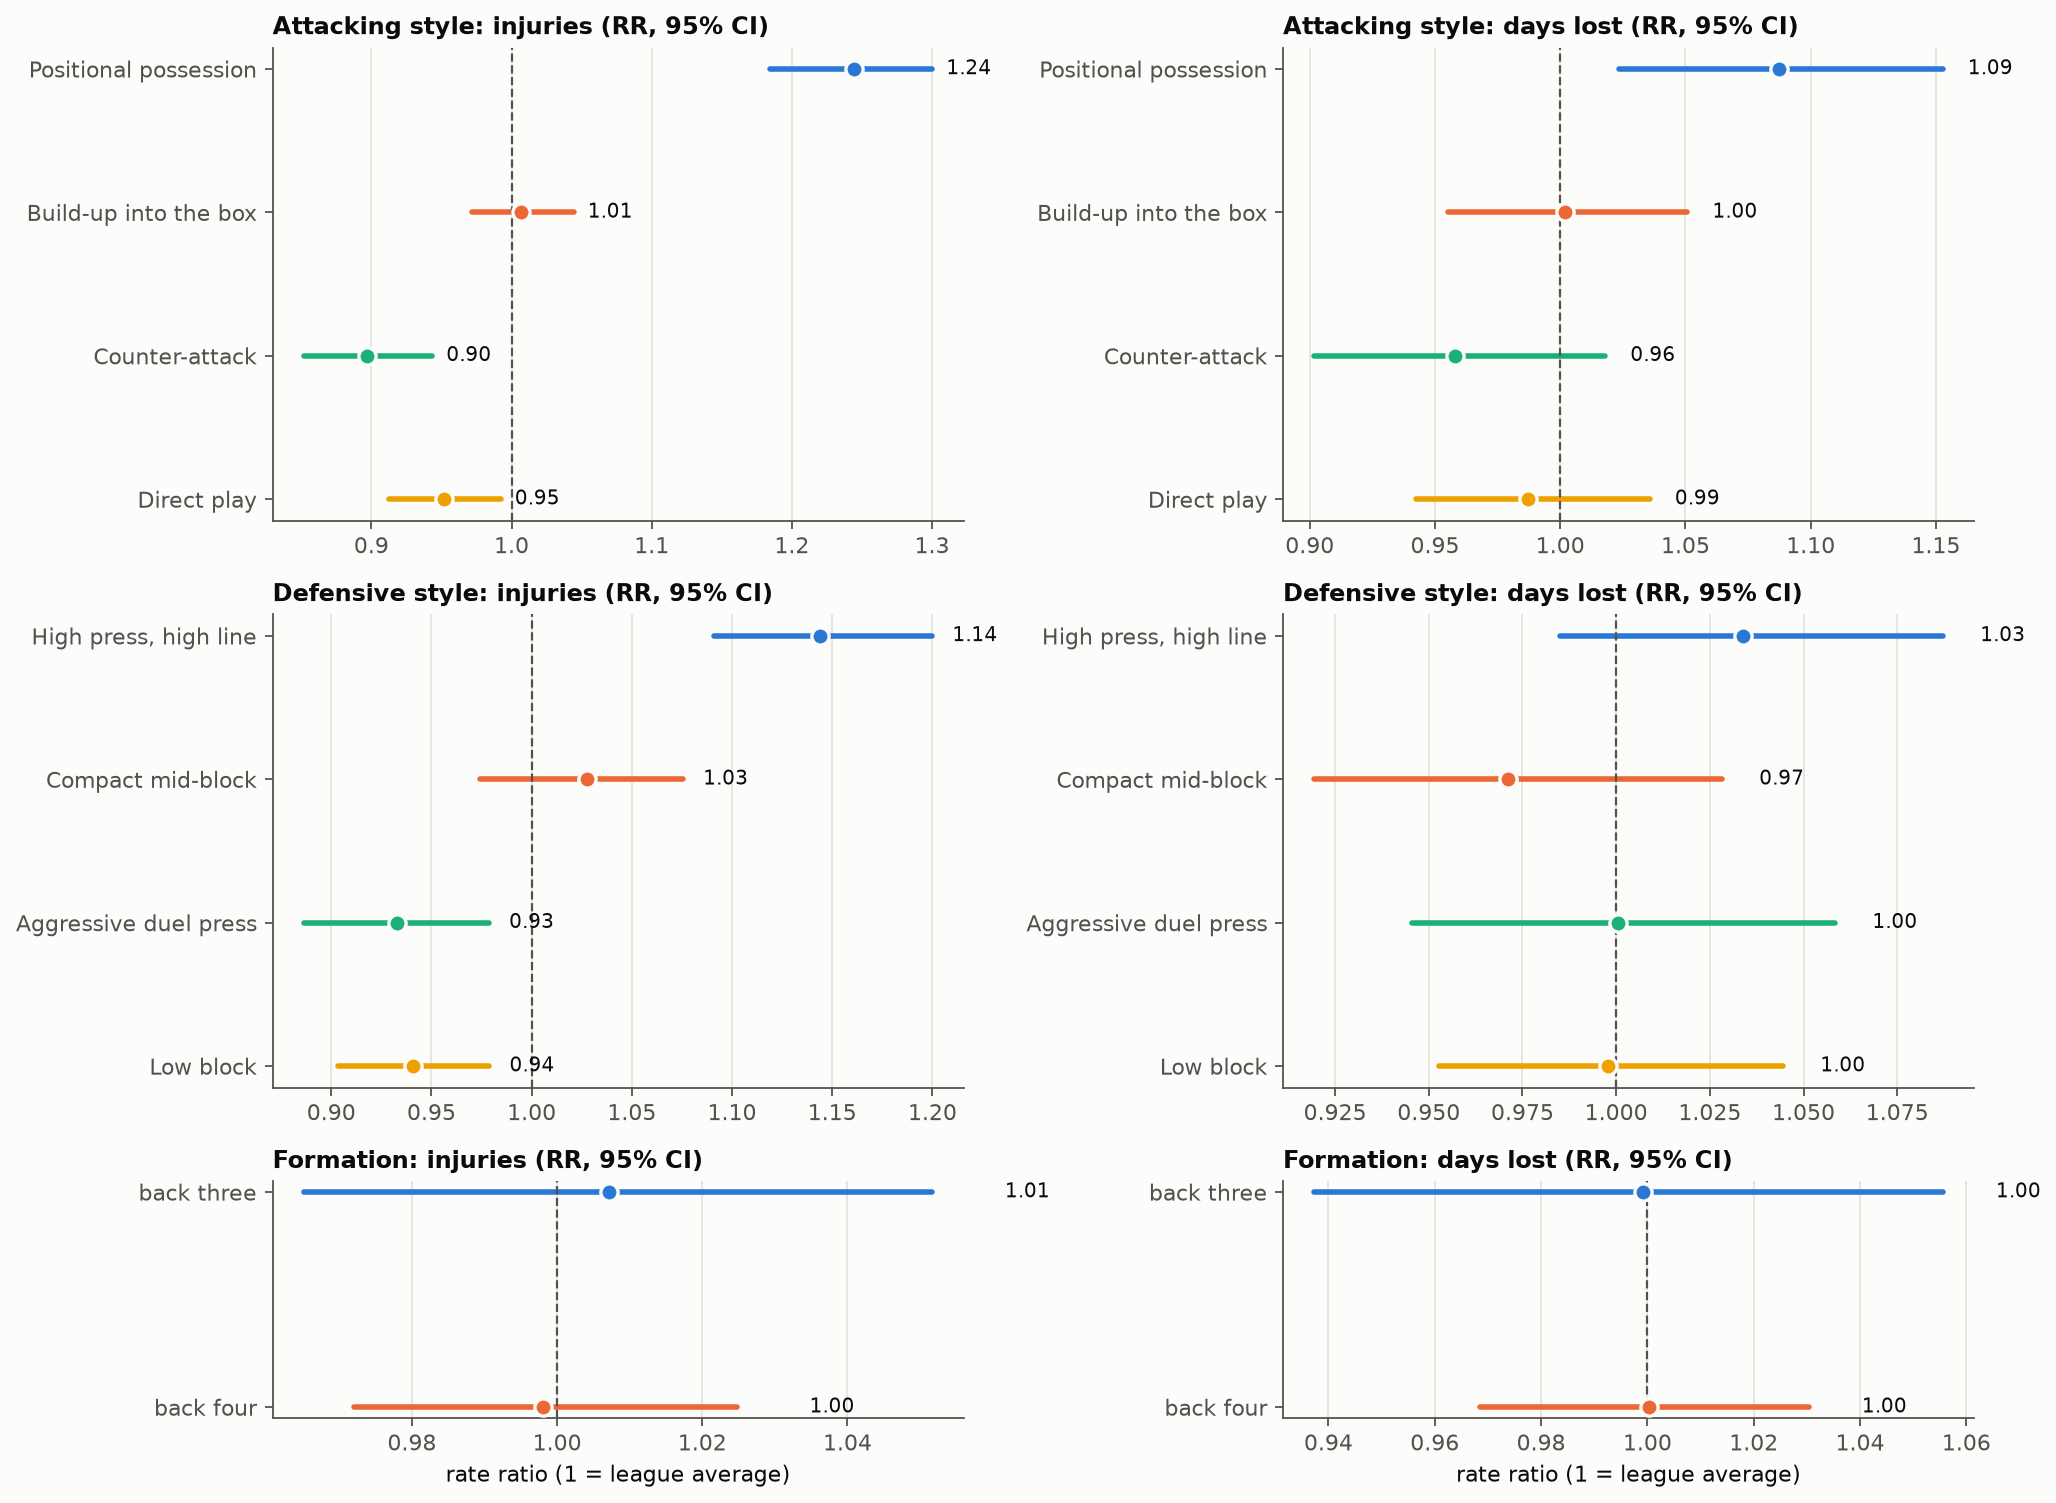

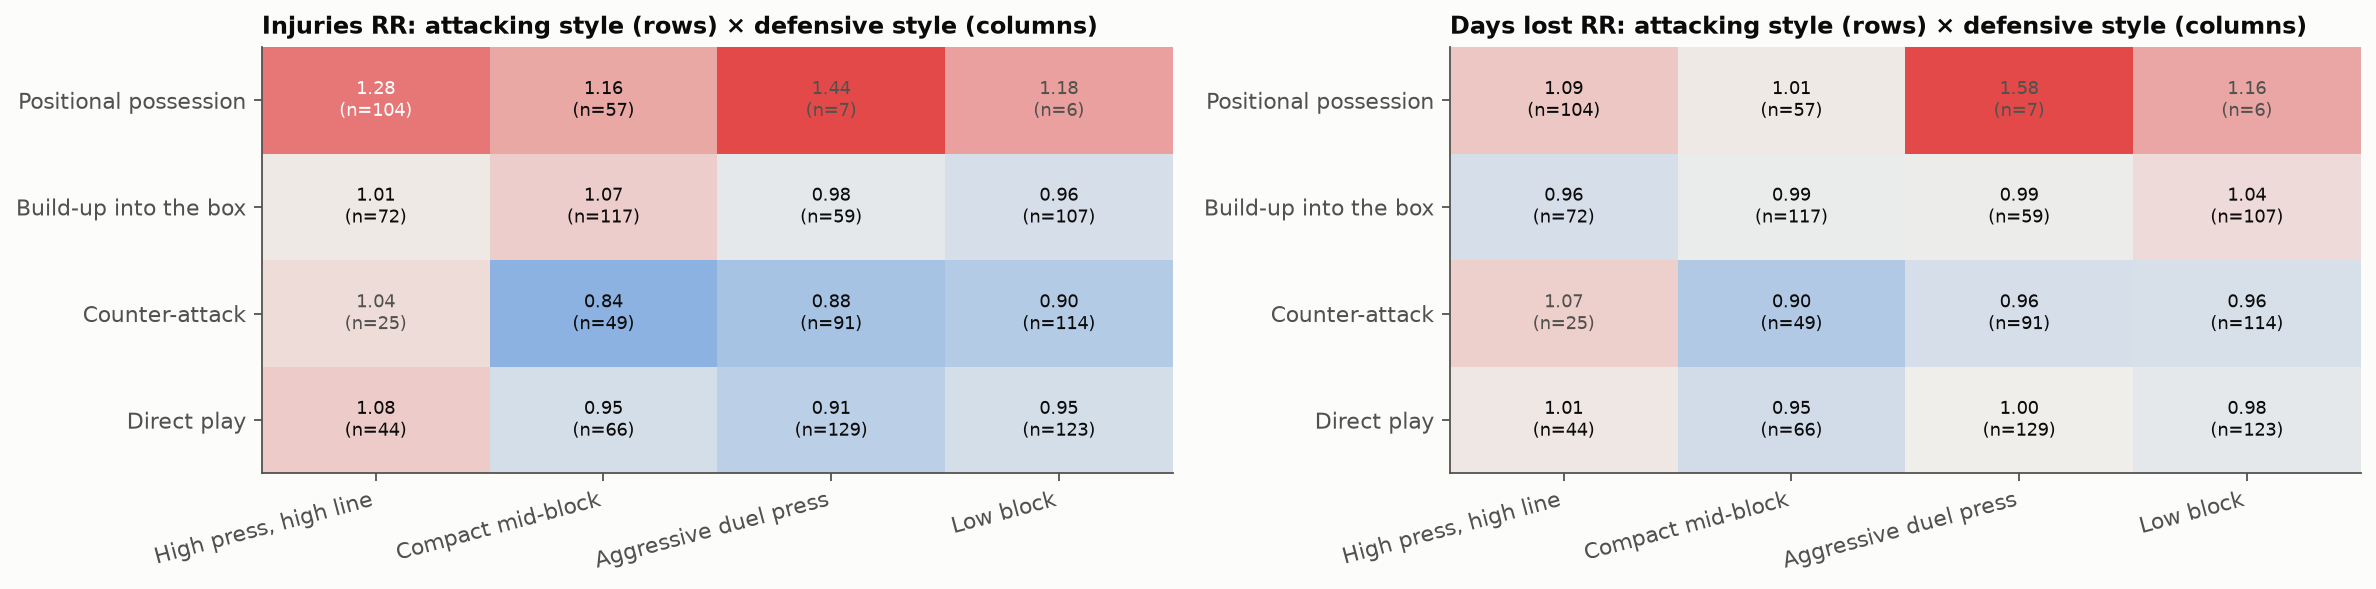

In [5]:
def ci_plot(ax, table: pd.DataFrame, rr: str, lo: str, hi: str, title: str, colors=SERIES) -> None:
    y = np.arange(len(table))[::-1]
    for yi, (name, r), color in zip(y, table.iterrows(), colors):
        ax.plot([r[lo], r[hi]], [yi, yi], color=color, linewidth=2.5, solid_capstyle="round")
        ax.scatter(r[rr], yi, s=60, color=color, edgecolors=SURFACE, linewidths=1.5, zorder=3)
        ax.text(r[hi] + 0.01, yi, f"{r[rr]:.2f}", va="center", fontsize=9, color=INK)
    ax.axvline(1, color=MUTED, linewidth=1, linestyle="--")
    ax.set_yticks(y, table.index)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)


fig, axes = plt.subplots(3, 2, figsize=(13, 9.5), gridspec_kw={"height_ratios": [4, 4, 2]})
for row, name in enumerate(["attacking style", "defensive style", "formation"]):
    t = results[name]
    ci_plot(axes[row, 0], t, "RR", "RR low", "RR high", f"{name.capitalize()}: injuries (RR, 95% CI)")
    ci_plot(axes[row, 1], t, "days RR", "days RR low", "days RR high", f"{name.capitalize()}: days lost (RR, 95% CI)")
for ax in axes[-1]:
    ax.set_xlabel("rate ratio (1 = league average)")
fig.tight_layout()
style_fig = save(fig, "05_rates_by_style.png")

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for ax, data, title in [(axes[0], grid_rr, "Injuries RR"), (axes[1], grid_days, "Days lost RR")]:
    vals = data.to_numpy(dtype=float)
    ax.imshow(np.log2(vals), cmap=DIVERGING, vmin=-0.5, vmax=0.5, aspect="auto")
    ax.set_xticks(range(len(DEFENCE)), DEFENCE, rotation=15, ha="right")
    ax.set_yticks(range(len(ATTACK)), ATTACK)
    ax.grid(False)
    for (i, j), v in np.ndenumerate(vals):
        n = grid_n.to_numpy()[i, j]
        ax.text(j, i, f"{v:.2f}\n(n={int(n)})", ha="center", va="center", fontsize=8,
                color=MUTED if n < 40 else (INK if abs(np.log2(v)) < 0.35 else "white"))
    ax.set_title(f"{title}: attacking style (rows) × defensive style (columns)", loc="left")
fig.tight_layout()
grid_fig = save(fig, "05_attack_defence_grid.png")

## Step 4. Body areas by style (within leagues)

Leagues label injuries very differently (*unspecified muscle* is 29% of La Liga injuries, 7% of Premier League
ones), so for each style and body area the share is taken **within each league**, relative to that league's share
(1 = same), summarised by the median over leagues and the number of leagues above 1. A pattern in 4–5 leagues is a
style pattern; one that flips is labelling. The pooled chi-square and Cramér's V give the overall size.

In [6]:
AREA_COLS = [c for c in ps.columns if c.startswith("area: ")]
AREAS = (ps[AREA_COLS].sum().sort_values(ascending=False).rename(index=lambda c: c[6:]).drop("unknown").index[:8].tolist())


def within_league_areas(col: str, order: list[str], data: pd.DataFrame = ps) -> tuple[pd.DataFrame, pd.DataFrame]:
    medians, above = {}, {}
    for a in AREAS:
        g = data.groupby(["league", col])[[f"area: {a}", "injuries"]].sum()
        lg = data.groupby("league")[[f"area: {a}", "injuries"]].sum()
        rel = (g[f"area: {a}"] / g.injuries).unstack().div(lg[f"area: {a}"] / lg.injuries, axis=0).reindex(columns=order)
        medians[a], above[a] = rel.median(), (rel > 1).sum()
    return pd.DataFrame(medians).loc[order], pd.DataFrame(above).loc[order]


def pooled_test(col: str, order: list[str], data: pd.DataFrame = ps) -> tuple[float, float]:
    known = data.groupby(col)[[f"area: {a}" for a in AREAS]].sum().loc[order]
    stat, p, dof, _ = chi2_contingency(known)
    return p, np.sqrt(stat / (known.to_numpy().sum() * (min(known.shape) - 1)))


body = {}
for name, (col, order) in GROUPINGS.items():
    data = ps[~ps.rare_style] if col == "style" else ps
    med, above = within_league_areas(col, order, data)
    p, v = pooled_test(col, order, data)
    body[name] = {"median": med, "above": above, "p": p, "V": v}
    print(f"\n{name}: pooled chi² p = {p:.2g}, Cramér's V = {v:.3f}")
    display(med.round(2))
    display(above)


attacking style: pooled chi² p = 6.3e-08, Cramér's V = 0.036


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body
attack_style,,,,,,,,
Positional possession,1.19,0.92,1.08,1.04,1.04,1.08,0.87,0.99
Build-up into the box,1.02,0.99,1.07,0.96,1.12,1.01,0.85,0.92
Counter-attack,0.81,1.02,0.91,1.05,0.93,0.86,1.08,1.10
Direct play,0.92,1.08,0.96,1.00,0.92,0.96,1.00,1.01


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body
attack_style,,,,,,,,
Positional possession,3,0,4,3,3,3,2,2
Build-up into the box,3,2,3,2,5,3,2,2
Counter-attack,1,5,2,4,1,1,3,5
Direct play,2,4,1,3,1,2,2,3



defensive style: pooled chi² p = 9.8e-22, Cramér's V = 0.051


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body
defence_style,,,,,,,,
"High press, high line",1.09,0.94,1.05,1.04,1.04,0.96,0.97,1.08
Compact mid-block,1.02,0.97,1.06,1.05,1.04,0.91,1.03,0.96
Aggressive duel press,0.93,1.11,0.97,0.96,0.94,1.03,0.96,0.98
Low block,0.90,1.03,0.80,0.92,0.99,1.10,1.05,0.90


...

,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body
style,,,,,,,,
"Positional possession · High press, high line",1.15,0.92,1.04,1.15,1.00,1.04,0.95,1.00
Positional possession · Compact mid-block,1.22,0.85,1.28,0.83,1.01,1.05,1.03,0.69
"Build-up into the box · High press, high line",1.03,0.93,1.11,1.01,1.25,0.91,0.85,0.98
Build-up into the box · Compact mid-block,1.12,1.02,1.08,1.09,0.96,0.89,0.86,0.89
Build-up into the box · Aggressive duel press,0.84,1.08,1.21,0.95,1.05,1.03,1.73,0.79
Build-up into the box · Low block,0.84,1.02,0.98,0.92,1.03,1.18,1.03,1.00
Counter-attack · Compact mid-block,0.89,1.03,0.80,1.18,1.19,0.49,1.27,1.32
Counter-attack · Aggressive duel press,0.91,1.15,0.95,1.02,0.87,0.97,1.04,1.07
Counter-attack · Low block,1.05,1.03,0.92,0.88,0.89,1.04,1.18,1.22


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body
style,,,,,,,,
"Positional possession · High press, high line",3,0,4,3,3,3,2,2
Positional possession · Compact mid-block,5,0,3,2,3,3,3,0
"Build-up into the box · High press, high line",3,1,4,3,5,2,1,2
Build-up into the box · Compact mid-block,4,4,4,4,2,1,2,2
Build-up into the box · Aggressive duel press,2,3,4,2,4,3,3,1
Build-up into the box · Low block,1,3,2,1,3,4,3,1
Counter-attack · Compact mid-block,0,3,2,3,4,0,4,4
Counter-attack · Aggressive duel press,1,4,2,3,1,2,3,3
Counter-attack · Low block,3,3,2,1,1,3,3,4



formation: pooled chi² p = 0.00069, Cramér's V = 0.036


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body
formation,,,,,,,,
back three,1.04,0.94,1.04,0.93,0.98,1.02,0.91,0.94
back four,0.97,1.01,0.98,1.01,1.01,1.00,1.02,1.01


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body
formation,,,,,,,,
back three,3,2,3,1,1,3,2,2
back four,2,3,2,4,4,2,3,3


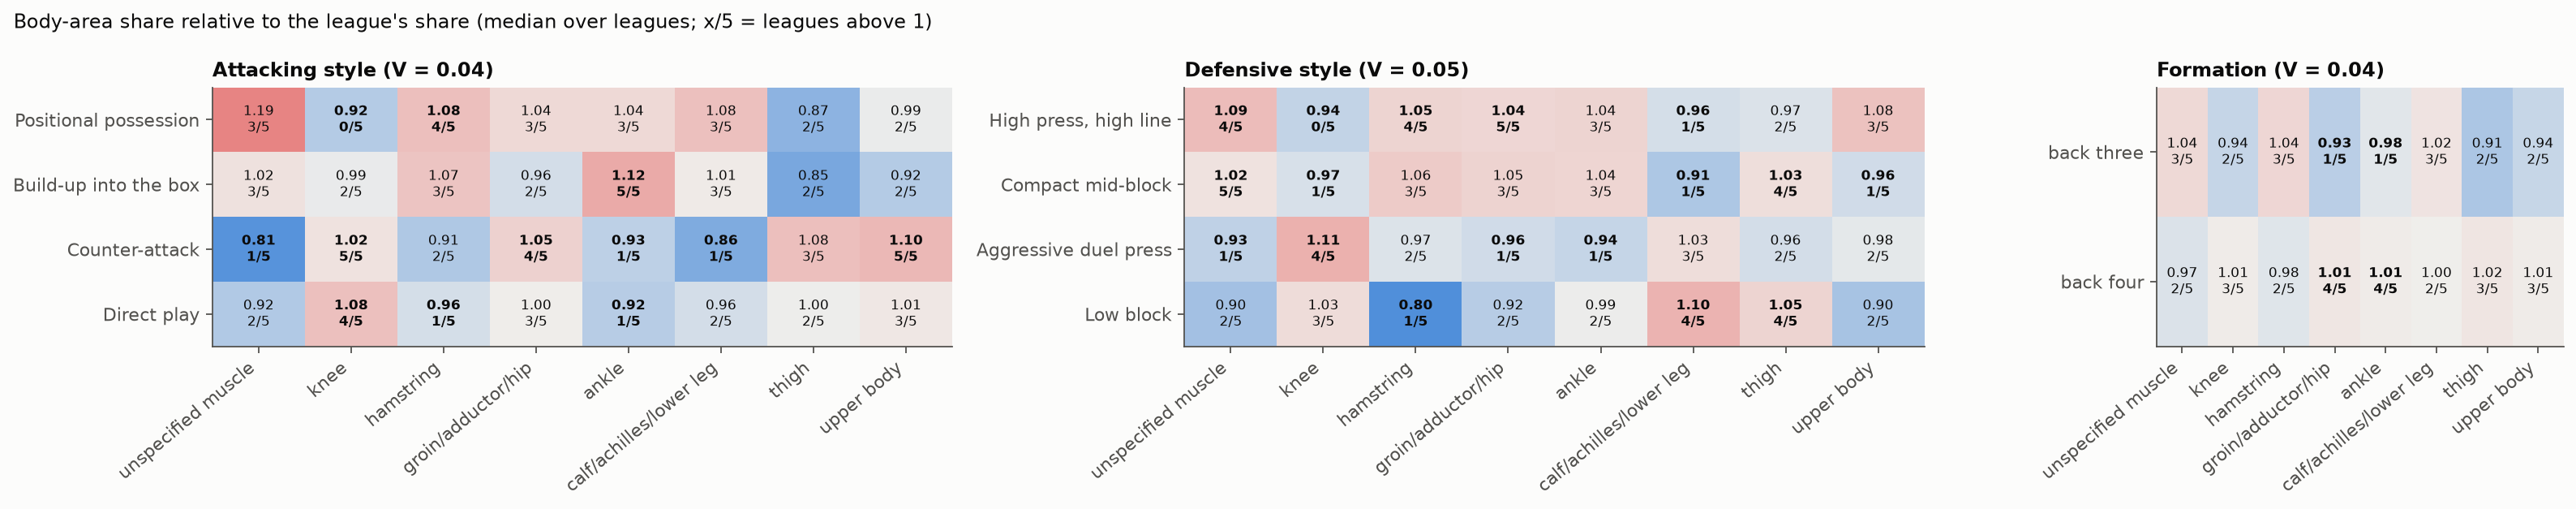

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4), gridspec_kw={"width_ratios": [1, 1, 0.55]})
for ax, name in zip(axes, ["attacking style", "defensive style", "formation"]):
    med, above = body[name]["median"], body[name]["above"]
    vals = med.to_numpy(dtype=float)
    ax.imshow(np.log2(vals), cmap=DIVERGING, vmin=-0.4, vmax=0.4, aspect="auto")
    ax.set_xticks(range(len(AREAS)), AREAS, rotation=40, ha="right")
    ax.set_yticks(range(len(med)), med.index)
    ax.grid(False)
    for (i, j), v in np.ndenumerate(vals):
        k = above.to_numpy()[i, j]
        strong = k >= 4 or k <= 1
        ax.text(j, i, f"{v:.2f}\n{k}/5", ha="center", va="center", fontsize=7.5, color=INK, fontweight="bold" if strong else "normal")
    ax.set_title(f"{name.capitalize()} (V = {body[name]['V']:.2f})", loc="left")
fig.suptitle("Body-area share relative to the league's share (median over leagues; x/5 = leagues above 1)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
area_fig = save(fig, "05_body_areas_by_style.png")

## Step 5. Seasons

Injuries per player-season by season (with 95% CIs and calendar events) and the share of each attacking and
defensive style per league over the seasons. Raw season rates mix real change with Transfermarkt's recording changes
(Phase 0: the Premier League 2018-19 jump), so the unknown body-area share is shown with them.

In [8]:
by_season = summarise(ps, "season_key")
unknown_share = (ps.groupby("season_key")["area: unknown"].sum() / ps.groupby("season_key").injuries.sum()).rename("unknown body area")
season_league = ps.groupby(["season_key", "league"]).apply(lambda d: d.injuries.sum() / len(d), include_groups=False).unstack()[LEAGUES]
shares = {ph: pd.crosstab([clusters.league, clusters.season_key], clusters[col], normalize="index")[order]
          for ph, (col, order) in {"attack": ("attack_style", ATTACK), "defence": ("defence_style", DEFENCE)}.items()}
display(fmt(by_season)[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share", "RR (95% CI)"]].join(unknown_share.round(3)))
season_league.round(3)

,player-seasons,injuries / player-season,days lost / player-season,severe share,RR (95% CI),unknown body area
season_key,,,,,,
2014-15,2939,0.592,29.1,0.480,0.88 (0.81–0.96),0.157
2015-16,3008,0.610,29.6,0.458,0.91 (0.83–0.99),0.137
2016-17,3005,0.707,33.4,0.470,1.05 (0.98–1.13),0.123
2017-18,2997,0.672,29.6,0.427,1.00 (0.93–1.07),0.099
2018-19,2944,0.781,33.0,0.423,1.16 (1.06–1.26),0.138
2019-20,3032,0.714,31.9,0.429,1.06 (0.99–1.14),0.096
2020-21,3161,0.655,26.3,0.396,0.97 (0.89–1.05),0.156
2021-22,3233,0.594,25.7,0.445,0.88 (0.81–0.96),0.145
2022-23,3148,0.614,28.1,0.471,0.92 (0.85–0.99),0.142


league,Premier League,La Liga,Serie A,Bundesliga,Ligue 1
season_key,,,,,
2014-15,0.600,0.516,0.693,0.849,0.320
2015-16,0.505,0.654,0.776,0.783,0.356
2016-17,0.565,0.891,0.740,0.900,0.465
2017-18,0.567,0.773,0.753,0.926,0.354
2018-19,1.077,0.798,0.773,0.894,0.374
2019-20,0.899,0.677,0.816,0.765,0.392
2020-21,0.677,0.490,0.871,0.746,0.483
2021-22,0.501,0.473,0.862,0.663,0.456
2022-23,0.552,0.409,0.870,0.673,0.568


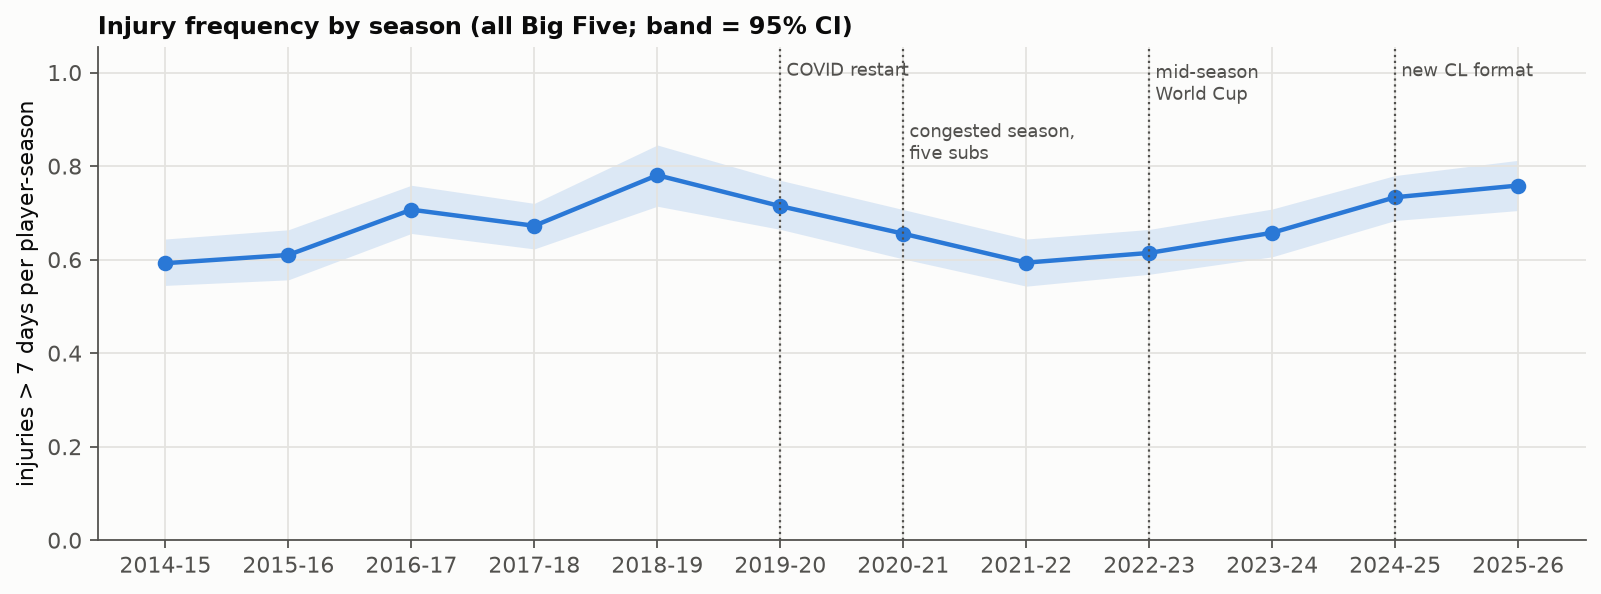

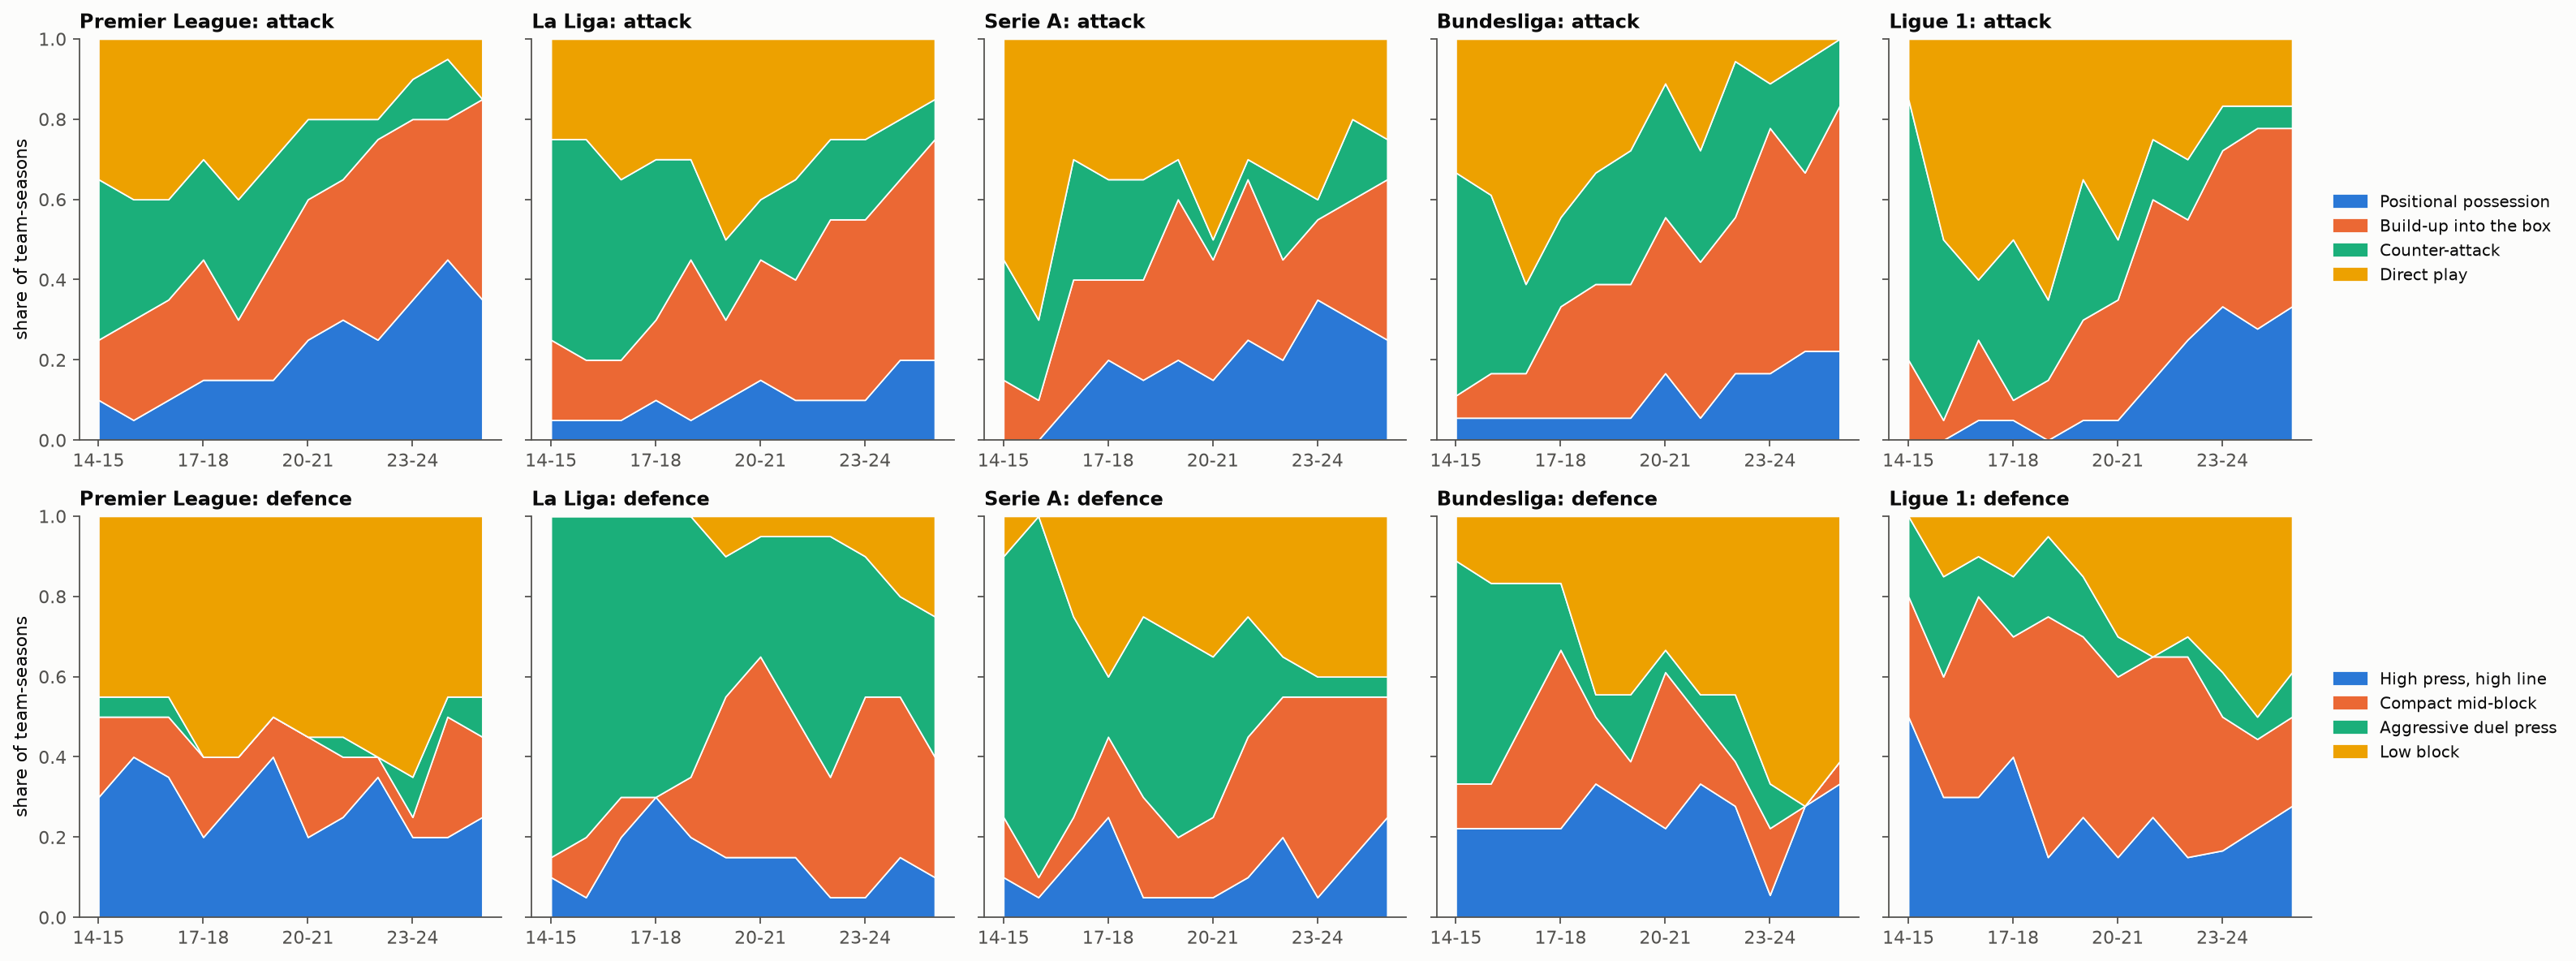

In [9]:
EVENTS = {"2019-20": "COVID restart", "2020-21": "congested season,\nfive subs", "2022-23": "mid-season\nWorld Cup", "2024-25": "new CL format"}
LABEL_Y = {"2019-20": 0.97, "2020-21": 0.85, "2022-23": 0.97, "2024-25": 0.97}
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(by_season))
rate = by_season["injuries / player-season"]
ax.fill_between(x, rate * by_season["RR low"] / by_season["RR"], rate * by_season["RR high"] / by_season["RR"], color=SERIES[0], alpha=0.15, linewidth=0)
ax.plot(x, rate, color=SERIES[0], marker="o", markersize=6)
ax.set_xticks(x, by_season.index)
ax.set_ylabel("injuries > 7 days per player-season")
ax.set_ylim(0, rate.max() * 1.35)
for s, label in EVENTS.items():
    xi = list(by_season.index).index(s)
    ax.axvline(xi, color=MUTED, linewidth=1, linestyle=":")
    ax.text(xi + 0.05, ax.get_ylim()[1] * LABEL_Y[s], label, fontsize=8, color=MUTED, va="top")
ax.set_title("Injury frequency by season (all Big Five; band = 95% CI)", loc="left")
trend_fig = save(fig, "05_season_trend.png")

fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), sharey=True)
for row, (ph, order) in enumerate([("attack", ATTACK), ("defence", DEFENCE)]):
    for ax, lg in zip(axes[row], LEAGUES):
        d = shares[ph].loc[lg].reindex(by_season.index).fillna(0)
        ax.stackplot(range(len(d)), d.T.to_numpy(), colors=SERIES[:4], edgecolor=SURFACE, linewidth=0.8)
        ax.set_title(f"{lg}: {ph}", loc="left")
        ax.set_xticks(range(0, len(d), 3), [d.index[i][2:] for i in range(0, len(d), 3)])
        ax.set_ylim(0, 1)
        ax.grid(False)
    axes[row, 0].set_ylabel("share of team-seasons")
    handles = [plt.Rectangle((0, 0), 1, 1, color=SERIES[i]) for i in range(4)]
    axes[row, 4].legend(handles, order, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)
fig.tight_layout()
shares_fig = save(fig, "05_style_shares_by_league.png")

## Step 6. Leagues

Rates per league (raw; partly recording) and each style's RR **within its own league** (its league's average = 1).
A pattern that holds in several leagues is more convincing than one carried by a single league.

In [10]:
by_league = summarise(ps, "league").loc[LEAGUES]
within = {}
for name in ["attacking style", "defensive style"]:
    col, order = GROUPINGS[name]
    t = summarise(ps, ["league", col])
    within[name] = (t["RR"].unstack().reindex(index=LEAGUES, columns=order), t["team-seasons"].unstack().reindex(index=LEAGUES, columns=order))
display(fmt(by_league)[COLS])
for name, (rr, n) in within.items():
    print(name)
    display(rr.round(2))

,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,excess / 100 player-seasons,excess days / player-season,RR (95% CI),days RR (95% CI)
league,,,,,,,,,,,
Premier League,7524,240,5151,0.685,0.451,36.2,0.512,0.0,0.0,1.00 (0.95–1.05),1.00 (0.94–1.06)
La Liga,7429,240,4451,0.599,0.402,26.9,0.448,0.0,0.0,1.00 (0.94–1.07),1.00 (0.93–1.06)
Serie A,7787,240,6410,0.823,0.608,30.4,0.371,0.0,0.0,1.00 (0.96–1.04),1.00 (0.95–1.05)
Bundesliga,6616,216,5227,0.790,0.593,37.7,0.474,0.0,0.0,1.00 (0.96–1.04),1.00 (0.95–1.05)
Ligue 1,7169,234,3342,0.466,0.334,21.5,0.452,-0.0,0.0,1.00 (0.93–1.07),1.00 (0.93–1.08)


attacking style


attack_style,Positional possession,Build-up into the box,Counter-attack,Direct play
league,,,,
Premier League,1.25,0.94,0.91,0.93
La Liga,1.61,1.01,0.88,0.89
Serie A,1.08,0.98,0.97,0.99
Bundesliga,1.08,1.01,0.95,1.01
Ligue 1,1.47,1.17,0.71,0.90


defensive style


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
league,,,,
Premier League,1.16,1.03,1.08,0.90
La Liga,1.42,1.12,0.89,0.50
Serie A,0.95,1.08,0.94,1.02
Bundesliga,1.06,1.04,0.97,0.96
Ligue 1,1.22,0.87,0.93,1.01


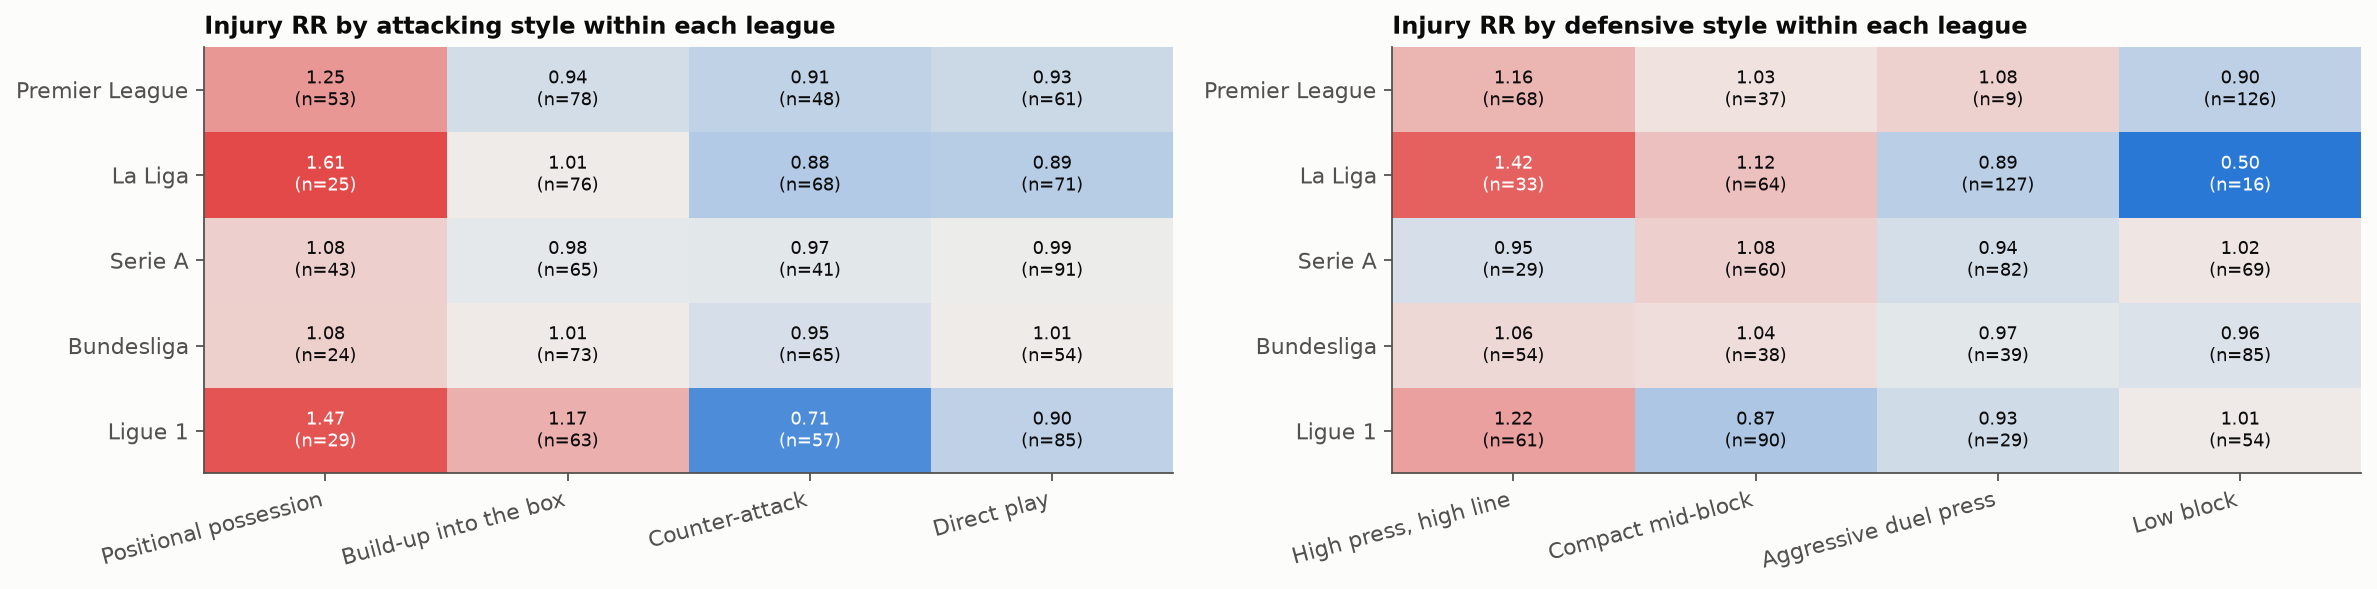

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for ax, (name, (rr, n)) in zip(axes, within.items()):
    vals = rr.to_numpy(dtype=float)
    ax.imshow(np.log2(vals), cmap=DIVERGING, vmin=-0.6, vmax=0.6, aspect="auto")
    ax.set_xticks(range(rr.shape[1]), rr.columns, rotation=15, ha="right")
    ax.set_yticks(range(len(LEAGUES)), LEAGUES)
    ax.grid(False)
    for (i, j), v in np.ndenumerate(vals):
        k = n.to_numpy()[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:.2f}\n(n={int(k)})", ha="center", va="center", fontsize=8,
                color=INK if np.isnan(v) or abs(np.log2(v)) < 0.45 else "white")
    ax.set_title(f"Injury RR by {name} within each league", loc="left")
fig.tight_layout()
league_fig = save(fig, "05_style_within_league.png")

## Step 7. Age and position

If style differences were only squad make-up, they would shrink when expected injuries come from **league × age
band × position** instead of league alone.

In [12]:
adjusted = {}
for name in ["attacking style", "defensive style", "formation"]:
    col, order = GROUPINGS[name]
    lap_t = summarise(ps.dropna(subset=["exp_inj_lap"]), col, "_lap").loc[order]
    mix = pd.concat([ps.groupby(col).age.mean().round(1).rename("mean age"),
                     pd.crosstab(ps[col], ps.position, normalize="index").round(2)], axis=1).loc[order]
    adjusted[name] = pd.DataFrame({"RR, league": results[name]["RR"], "RR, league × age × position": lap_t["RR"],
                                   "days RR, league": results[name]["days RR"], "days RR, league × age × position": lap_t["days RR"]}).round(2).join(mix)
    display(adjusted[name])
display(fmt(summarise(ps.dropna(subset=["age_band"]), "age_band"))[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]])
fmt(summarise(ps.dropna(subset=["position"]), "position"))[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]]

,"RR, league","RR, league × age × position","days RR, league","days RR, league × age × position",mean age,Defender,Forward,Goalkeeper,Midfielder
attack_style,,,,,,,,,
Positional possession,1.24,1.27,1.09,1.11,25.7,0.34,0.26,0.09,0.31
Build-up into the box,1.01,1.02,1.00,1.01,25.7,0.34,0.28,0.08,0.30
Counter-attack,0.90,0.88,0.96,0.95,26.2,0.34,0.28,0.09,0.29
Direct play,0.95,0.94,0.99,0.98,26.0,0.33,0.29,0.08,0.30


,"RR, league","RR, league × age × position","days RR, league","days RR, league × age × position",mean age,Defender,Forward,Goalkeeper,Midfielder
defence_style,,,,,,,,,
"High press, high line",1.14,1.16,1.03,1.05,25.5,0.34,0.26,0.09,0.31
Compact mid-block,1.03,1.03,0.97,0.98,25.8,0.34,0.28,0.09,0.30
Aggressive duel press,0.93,0.93,1.00,1.00,26.1,0.34,0.28,0.09,0.30
Low block,0.94,0.93,1.00,0.99,26.1,0.34,0.29,0.08,0.29


,"RR, league","RR, league × age × position","days RR, league","days RR, league × age × position",mean age,Defender,Forward,Goalkeeper,Midfielder
formation,,,,,,,,,
back three,1.01,1.01,1.0,1.0,25.9,0.35,0.26,0.09,0.3
back four,1.00,1.00,1.0,1.0,25.9,0.34,0.28,0.09,0.3


,player-seasons,injuries / player-season,days lost / player-season,severe share
age_band,,,,
≤21,6166,0.365,19.6,0.519
22–25,10553,0.628,29.4,0.466
26–29,10525,0.774,34.4,0.432
30+,9260,0.814,34.5,0.426


,player-seasons,injuries / player-season,days lost / player-season,severe share
position,,,,
Defender,12362,0.755,34.5,0.448
Forward,10152,0.661,29.7,0.438
Goalkeeper,3127,0.418,21.3,0.511
Midfielder,10884,0.664,29.3,0.443


## Step 8. Team strength and workload

Styles follow team strength partly (Phase 4: eta² 0.39 attack, 0.34 defence). **Strength:** style RRs within each
third of teams by points per match. **Workload:** player-seasons in the busiest third (share of matches on < 4 days'
rest) vs the rest, overall and within each style.

In [13]:
ps["congestion"] = pd.qcut(ps.short_rest_share, 3, labels=["lightest third", "middle third", "busiest third"], duplicates="drop")
by_congestion = summarise(ps, "congestion")
strength_rr, congestion_rr = {}, {}
for name in ["attacking style", "defensive style"]:
    col, order = GROUPINGS[name]
    strength_rr[name] = summarise(ps, ["strength", col])["RR"].unstack().reindex(columns=order)
    congestion_rr[name] = summarise(ps, ["congestion", col])["RR"].unstack().reindex(columns=order)
    display(strength_rr[name].round(2))
    display(congestion_rr[name].round(2))
fmt(by_congestion)[COLS]

attack_style,Positional possession,Build-up into the box,Counter-attack,Direct play
strength,,,,
middle third,1.10,0.95,0.92,0.98
stronger third,1.25,1.10,1.00,1.09
weaker third,1.42,0.92,0.86,0.91


attack_style,Positional possession,Build-up into the box,Counter-attack,Direct play
congestion,,,,
busiest third,1.29,1.05,1.06,1.16
lightest third,1.06,1.00,0.91,0.91
middle third,1.21,0.95,0.81,0.89


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
strength,,,,
middle third,1.12,0.93,0.92,0.95
stronger third,1.19,1.13,1.15,1.01
weaker third,0.81,0.91,0.86,0.93


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
congestion,,,,
busiest third,1.23,1.13,1.13,0.95
lightest third,0.94,0.99,0.86,0.97
middle third,1.04,0.92,0.89,0.90


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,excess / 100 player-seasons,excess days / player-season,RR (95% CI),days RR (95% CI)
congestion,,,,,,,,,,,
lightest third,12400,397,8048,0.649,0.521,29.7,0.455,-4.1,-0.5,0.94 (0.91–0.98),0.98 (0.94–1.03)
middle third,11970,386,7200,0.602,0.437,28.5,0.459,-5.3,-1.6,0.92 (0.88–0.96),0.95 (0.90–1.00)
busiest third,12155,387,9333,0.768,0.469,33.2,0.431,9.4,2.1,1.14 (1.10–1.18),1.07 (1.02–1.11)


## Step 9. Fitness absences (secondary outcome)

*Fitness* absences (not injuries; mostly reconditioning) are recorded almost only in the Bundesliga, so they are
compared by style within the Bundesliga.

In [14]:
bl = ps[ps.league == "Bundesliga"]
fitness = {}
for name in ["attacking style", "defensive style"]:
    col, order = GROUPINGS[name]
    f = bl.groupby(col).agg(player_seasons=("playerId", "size"), fitness_absences=("fitness_absences", "sum")).reindex(order)
    f["per 100 player-seasons"] = (100 * f.fitness_absences / f.player_seasons).round(1)
    fitness[name] = f
    display(f)

,player_seasons,fitness_absences,per 100 player-seasons
attack_style,,,
Positional possession,733,73,10.0
Build-up into the box,2244,235,10.5
Counter-attack,1957,198,10.1
Direct play,1682,214,12.7


,player_seasons,fitness_absences,per 100 player-seasons
defence_style,,,
"High press, high line",1646,185,11.2
Compact mid-block,1149,115,10.0
Aggressive duel press,1198,136,11.4
Low block,2623,284,10.8


## Step 10. Sensitivity checks

The league-adjusted RR per style under each variation; a finding is robust if its direction holds in every row.

In [15]:
def rr_variant(df: pd.DataFrame, col: str, order: list[str], count: str = "injuries") -> pd.Series:
    d = add_expected(df.assign(injuries=df[count]), ["league"])
    return summarise(d, col)["RR"].reindex(order)


VARIANTS = {
    "main (> 7 days)": lambda d: (d, "injuries"),
    "≥ 900 minutes only": lambda d: (d[d.minutes >= 900], "injuries"),
    "severe only (> 28 days)": lambda d: (d, "severe"),
    "> 3 days (adds mild)": lambda d: (d.assign(more=d.injuries + d.mild_injuries), "more"),
    "multi-club players out": lambda d: (d[d.clubs_in_season == 1], "injuries"),
    "COVID seasons out": lambda d: (d[~d.season_key.isin(COVID_SEASONS)], "injuries"),
}
sensitivity, robust = {}, {}
for name in ["attacking style", "defensive style", "formation"]:
    col, order = GROUPINGS[name]
    sensitivity[name] = pd.DataFrame({v: rr_variant(data, col, order, count) for v, (data, count) in
                                      ((v, f(ps)) for v, f in VARIANTS.items())}).T.round(2)
    signs = np.sign(sensitivity[name] - 1)
    robust[name] = [s for s in order if signs[s].nunique() == 1 and signs[s].iloc[0] != 0]
    display(sensitivity[name])
    print("same direction in every variant:", robust[name])

attack_style,Positional possession,Build-up into the box,Counter-attack,Direct play
main (> 7 days),1.24,1.01,0.90,0.95
≥ 900 minutes only,1.30,1.01,0.87,0.93
severe only (> 28 days),1.09,1.00,0.94,1.00
> 3 days (adds mild),1.30,1.01,0.88,0.93
multi-club players out,1.27,1.01,0.89,0.94
COVID seasons out,1.24,1.03,0.89,0.94


same direction in every variant: ['Positional possession', 'Counter-attack']


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
main (> 7 days),1.14,1.03,0.93,0.94
≥ 900 minutes only,1.19,1.05,0.91,0.90
severe only (> 28 days),1.05,0.96,1.00,0.99
> 3 days (adds mild),1.19,1.04,0.91,0.92
multi-club players out,1.16,1.03,0.94,0.93
COVID seasons out,1.15,1.04,0.93,0.93


same direction in every variant: ['High press, high line', 'Low block']


formation,back three,back four
main (> 7 days),1.01,1.00
≥ 900 minutes only,1.02,0.99
severe only (> 28 days),0.97,1.01
> 3 days (adds mild),1.01,1.00
multi-club players out,1.01,1.00
COVID seasons out,1.02,0.99


same direction in every variant: []


## Step 11. Style cards: what each style looks like on the pitch

Each style is described from its **clear members** (core): team-seasons whose fuzzy membership in their own style is
at least 0.5 (Phase 4, fuzzy c-means memberships from the K-means centroids). Typical teams are the ones with the
highest membership in each era. A card gives the defining traits in football terms, the matching numbers in real
units against the all-team average, formation, strength, and the styles of the other phase it is most often paired with.

In [16]:
CLEAR = 0.5  # fuzzy membership from which a team-season is a clear member of its style (Phase 4)
RAW = {"attack_possession": ("deep_pm", "deep completions per match"), "attack_patience": ("slow_attack_share", "shots from slow, patient attacks"),
       "attack_verticality": ("fast_attack_share", "shots from fast attacks"), "attack_directness": ("outside_box_share", "shots from outside the box"),
       "defence_press": ("ppda", "PPDA (lower = more pressing)"), "defence_high_line": ("conceded_fast_share", "shots conceded from fast attacks"),
       "defence_territory_conceded": ("deep_against_pm", "deep completions conceded per match"), "defence_aggression": ("fouls_pm", "fouls per match")}
PHRASE = {"attack_possession": ("dominates the ball and plays in the opponent's half", "spends long spells without the ball"),
          "attack_patience": ("builds up slowly and patiently", "rarely builds up slowly"),
          "attack_verticality": ("attacks fast and vertically, on the break", "rarely attacks at speed"),
          "attack_directness": ("shoots from distance and relies on set plays", "works the ball into the box before shooting"),
          "defence_press": ("presses high and wins the ball back quickly", "sits off and lets the opponent have the ball"),
          "defence_high_line": ("holds a high line, exposed to counters", "keeps a deep, protected line"),
          "defence_territory_conceded": ("lets opponents near the box", "keeps opponents far from goal"),
          "defence_aggression": ("defends through fouls and duels, many cards", "defends cleanly, few fouls")}
ts = team.merge(features[["season", "club_id"] + [r for r, _ in RAW.values()]], on=["season", "club_id"])
for ph in ["attack", "defence"]:
    ts[f"{ph}_core"] = ts[f"{ph}_membership"] >= CLEAR
    ts[f"{ph}_dist"] = -ts[f"{ph}_membership"]  # sort key: highest membership first


def value(feature: str, v: float) -> str:
    return f"{100 * v:.0f}%" if feature.endswith("share") else f"{v:.1f}"


cards = {}
for ph, col, order, other in [("attack", "attack_style", ATTACK, "defence_style"), ("defence", "defence_style", DEFENCE, "attack_style")]:
    rows = []
    for name in order:
        s = ts[ts[col] == name]
        core = s[s[f"{ph}_core"]]
        cz = core[DIMS[ph]].mean()
        top = cz.abs().sort_values(ascending=False).index[:3]
        typical = (core.sort_values(f"{ph}_dist").groupby("era").head(2).assign(t=lambda d: d.club + " " + d.season_key)
                   .groupby("era").t.apply(", ".join).reindex(ERA_ORDER).fillna("–"))
        pairs = s[other].value_counts(normalize=True).head(2)
        rows.append({"style": name, "team-seasons": len(s), "core": f"{len(core)} ({len(core) / len(s):.0%})",
                     "how it plays": "; ".join(PHRASE[d][0 if cz[d] > 0 else 1] for d in top),
                     "in numbers (core)": "; ".join(f"{RAW[d][1]}: {value(RAW[d][0], core[RAW[d][0]].mean())} (all {value(RAW[d][0], ts[RAW[d][0]].mean())})" for d in top),
                     "back-three minutes": f"{100 * s.back_three_share.mean():.0f}%", "points/match": round(core.points_pm.mean(), 2),
                     "most often with": ", ".join(f"{k} ({v:.0%})" for k, v in pairs.items()),
                     **{f"typical {e}": typical[e] for e in ERA_ORDER}})
    cards[ph] = pd.DataFrame(rows).set_index("style")
    display(cards[ph])
ps = ps.merge(ts[["season", "club_id", "attack_core", "defence_core"]], on=["season", "club_id"], how="left")
core_check = {}
for ph, name in [("attack", "attacking style"), ("defence", "defensive style")]:
    col, order = GROUPINGS[name]
    core_t = summarise(ps[ps[f"{ph}_core"]], col).loc[order]
    core_check[name] = pd.DataFrame({"RR, all teams": results[name]["RR"], "RR, core teams": core_t["RR"],
                                     "days RR, all teams": results[name]["days RR"], "days RR, core teams": core_t["days RR"]}).round(2)
    display(core_check[name])

,team-seasons,core,how it plays,in numbers (core),back-three minutes,points/match,most often with,typical 2014–18,typical 2018–22,typical 2022–26
style,,,,,,,,,,
Positional possession,174,118 (68%),dominates the ball and plays in the opponent's half; builds up slowly and patiently; works the ball into the box before shooting,"deep completions per match: 10.0 (all 6.1); shots from slow, patient attacks: 9% (all 6%); shots from outside the box: 33% (all 38%)",23%,2.03,"High press, high line (60%), Compact mid-block (33%)","SSC Napoli 2017-18, FC Barcelona 2014-15","Atalanta BC 2021-22, FC Barcelona 2020-21","Borussia Dortmund 2022-23, SSC Napoli 2022-23"
Build-up into the box,355,148 (42%),works the ball into the box before shooting; dominates the ball and plays in the opponent's half; builds up slowly and patiently,"shots from outside the box: 34% (all 38%); deep completions per match: 6.8 (all 6.1); shots from slow, patient attacks: 6% (all 6%)",29%,1.49,"Compact mid-block (33%), Low block (30%)","Borussia Mönchengladbach 2017-18, Olympique Marseille 2016-17","LOSC Lille 2021-22, Leicester City 2021-22","TSG 1899 Hoffenheim 2023-24, AFC Bournemouth 2025-26"
Counter-attack,279,193 (69%),"attacks fast and vertically, on the break; rarely builds up slowly; spends long spells without the ball","shots from fast attacks: 8% (all 6%); shots from slow, patient attacks: 4% (all 6%); deep completions per match: 4.6 (all 6.1)",18%,1.15,"Low block (41%), Aggressive duel press (33%)","Rayo Vallecano 2014-15, RCD Espanyol Barcelona 2014-15","Burnley FC 2019-20, Dijon FCO 2019-20","Cagliari Calcio 2023-24, RCD Mallorca 2023-24"
Direct play,362,244 (67%),shoots from distance and relies on set plays; rarely attacks at speed; spends long spells without the ball,shots from outside the box: 42% (all 38%); shots from fast attacks: 5% (all 6%); deep completions per match: 4.7 (all 6.1),22%,1.11,"Aggressive duel press (36%), Low block (34%)","Swansea City 2014-15, Norwich City 2015-16","Arminia Bielefeld 2021-22, AS Saint-Étienne 2020-21","Genoa CFC 2023-24, Elche CF 2022-23"


,team-seasons,core,how it plays,in numbers (core),back-three minutes,points/match,most often with,typical 2014–18,typical 2018–22,typical 2022–26
style,,,,,,,,,,
"High press, high line",245,137 (56%),"holds a high line, exposed to counters; keeps opponents far from goal; presses high and wins the ball back quickly",shots conceded from fast attacks: 8% (all 6%); deep completions conceded per match: 4.6 (all 6.1); PPDA (lower = more pressing): 8.8 (all 10.9),18%,1.85,"Positional possession (42%), Build-up into the box (29%)","Stade Rennais FC 2016-17, Real Sociedad 2017-18","Atalanta BC 2018-19, FC Barcelona 2018-19","Brighton & Hove Albion 2022-23, Juventus FC 2024-25"
Compact mid-block,289,136 (47%),"keeps a deep, protected line; keeps opponents far from goal; defends cleanly, few fouls",shots conceded from fast attacks: 5% (all 6%); deep completions conceded per match: 5.2 (all 6.1); fouls per match: 12.3 (all 12.5),27%,1.58,"Build-up into the box (40%), Direct play (23%)","SV Werder Bremen 2017-18, FC Girondins Bordeaux 2016-17","Borussia Mönchengladbach 2019-20, Stade Rennais FC 2018-19","Atlético de Madrid 2025-26, Stade Rennais FC 2023-24"
Aggressive duel press,286,175 (61%),"defends through fouls and duels, many cards; presses high and wins the ball back quickly; holds a high line, exposed to counters",fouls per match: 14.8 (all 12.5); PPDA (lower = more pressing): 9.3 (all 10.9); shots conceded from fast attacks: 6% (all 6%),20%,1.24,"Direct play (45%), Counter-attack (32%)","Inter Milan 2015-16, SV Werder Bremen 2015-16","Real Betis Balompié 2019-20, Rayo Vallecano 2018-19","Deportivo Alavés 2025-26, Rayo Vallecano 2025-26"
Low block,350,231 (66%),"sits off and lets the opponent have the ball; lets opponents near the box; defends cleanly, few fouls",PPDA (lower = more pressing): 13.7 (all 10.9); deep completions conceded per match: 7.8 (all 6.1); fouls per match: 11.5 (all 12.5),27%,1.04,"Direct play (35%), Counter-attack (33%)","Hull City 2014-15, SC Freiburg 2016-17","Everton FC 2021-22, Brighton & Hove Albion 2018-19","AJ Auxerre 2024-25, Stade Reims 2024-25"


,"RR, all teams","RR, core teams","days RR, all teams","days RR, core teams"
attack_style,,,,
Positional possession,1.24,1.25,1.09,1.08
Build-up into the box,1.01,1.06,1.00,1.03
Counter-attack,0.90,0.88,0.96,0.94
Direct play,0.95,0.93,0.99,1.00


,"RR, all teams","RR, core teams","days RR, all teams","days RR, core teams"
defence_style,,,,
"High press, high line",1.14,1.17,1.03,1.08
Compact mid-block,1.03,1.06,0.97,1.00
Aggressive duel press,0.93,0.96,1.00,1.03
Low block,0.94,0.94,1.00,0.97


## Step 12. How the ways of attacking and defending changed, and in what shape

Each dimension's mean per era (2014–18, 2018–22, 2022–26), for all leagues and per league, with the shape: **rising**,
**falling**, **peak** (up then down), **dip** (down then up) or **flat** (every step under 0.1 SD). Real-unit means
show the same changes in football terms.

In [17]:
SHAPE_TOL = 0.1
ALL_DIMS = DIMS["attack"] + DIMS["defence"]


def shape(values: list[float]) -> str:
    steps = [0 if abs(d) < SHAPE_TOL else int(np.sign(d)) for d in np.diff(values)]
    if steps == [0, 0]:
        return "flat"
    if all(s >= 0 for s in steps):
        return "rising"
    if all(s <= 0 for s in steps):
        return "falling"
    return "peak" if steps == [1, -1] else "dip"


era_dims = ts.groupby(["league", "era"])[ALL_DIMS].mean()
era_all = ts.groupby("era")[ALL_DIMS].mean().loc[ERA_ORDER]
shapes = pd.DataFrame({lg: {d: shape(era_dims.loc[lg].loc[ERA_ORDER, d].tolist()) for d in ALL_DIMS} for lg in LEAGUES})
shapes.insert(0, "all leagues", [shape(era_all[d].tolist()) for d in ALL_DIMS])
raw_by_era = ts.groupby("era")[[r for r, _ in RAW.values()] + ["back_three_share"]].mean().loc[ERA_ORDER].T
raw_by_era.index = [RAW[d][1] for d in ALL_DIMS] + ["minutes in a back three"]
display(era_all.T.round(2).assign(shape=shapes["all leagues"]))
display(shapes)
raw_by_era.round(3)

era,2014–18,2018–22,2022–26,shape
attack_possession,-0.19,0.03,0.16,rising
attack_patience,-0.65,-0.02,0.68,rising
attack_verticality,0.09,-0.02,-0.07,falling
attack_directness,0.47,0.01,-0.49,falling
defence_press,0.53,-0.10,-0.44,falling
defence_high_line,0.08,-0.03,-0.06,falling
defence_territory_conceded,-0.08,-0.02,0.10,rising
defence_aggression,0.24,-0.05,-0.20,falling


,all leagues,Premier League,La Liga,Serie A,Bundesliga,Ligue 1
attack_possession,rising,rising,rising,peak,rising,rising
attack_patience,rising,rising,rising,rising,rising,rising
attack_verticality,falling,falling,falling,falling,rising,falling
attack_directness,falling,falling,falling,falling,falling,falling
defence_press,falling,falling,falling,falling,falling,falling
defence_high_line,falling,falling,falling,falling,rising,falling
defence_territory_conceded,rising,rising,dip,peak,rising,rising
defence_aggression,falling,dip,falling,falling,falling,falling


era,2014–18,2018–22,2022–26
deep completions per match,5.701,6.046,6.534
"shots from slow, patient attacks",0.044,0.057,0.071
shots from fast attacks,0.062,0.060,0.060
shots from outside the box,0.413,0.376,0.344
PPDA (lower = more pressing),9.660,11.116,11.894
shots conceded from fast attacks,0.062,0.061,0.060
deep completions conceded per match,5.701,6.045,6.534
fouls per match,13.314,12.376,11.866
minutes in a back three,0.134,0.257,0.311


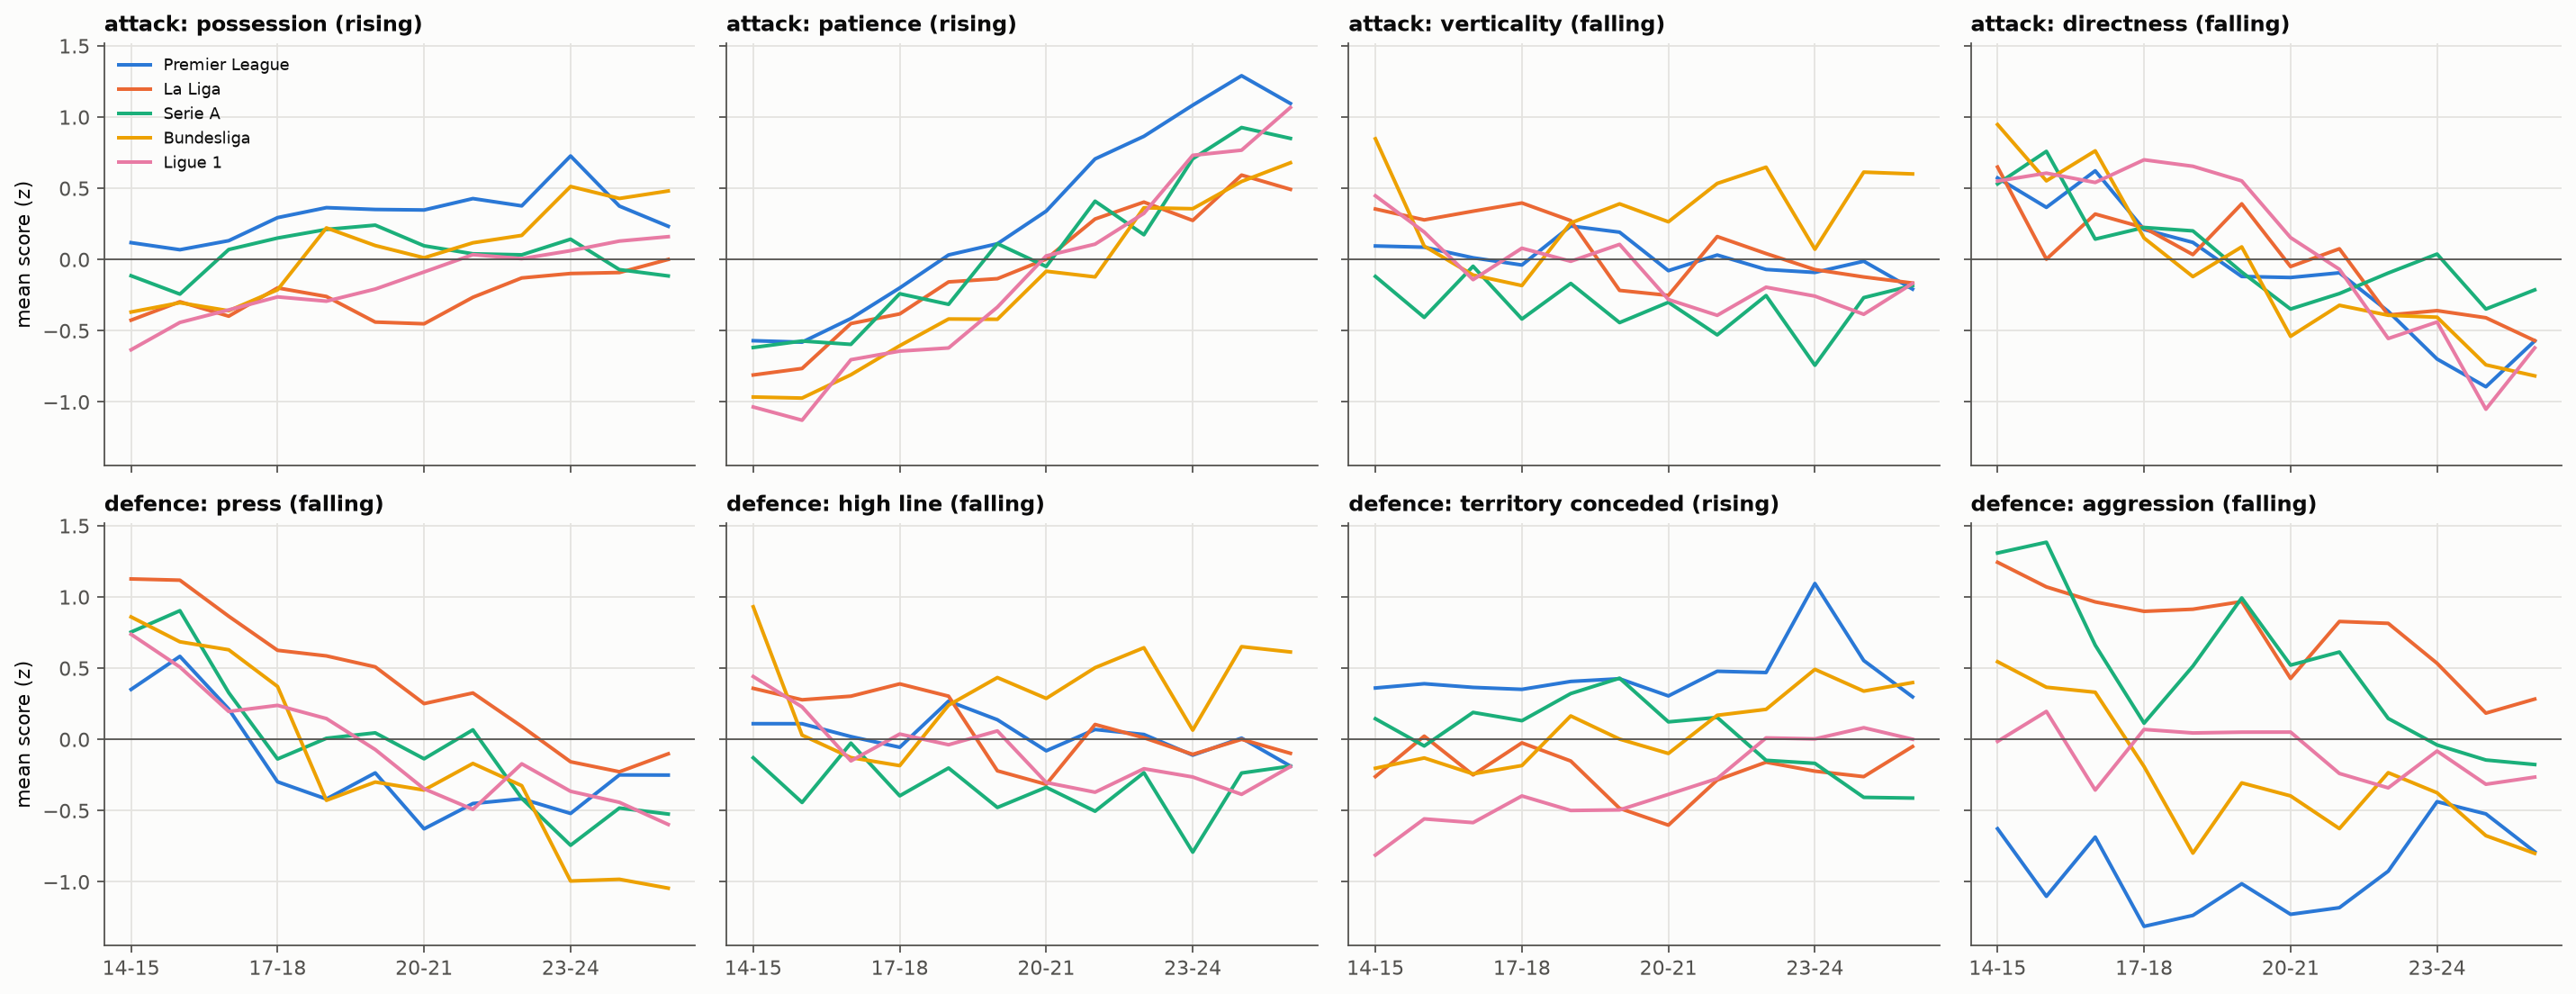

In [18]:
LEAGUE_COLORS = dict(zip(LEAGUES, SERIES))
season_dims = ts.groupby(["season_key", "league"])[ALL_DIMS].mean()
seasons_x = sorted(ts.season_key.unique())
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
for ax, d in zip(axes.flat, ALL_DIMS):
    for lg in LEAGUES:
        y = season_dims[d].xs(lg, level="league").reindex(seasons_x)
        ax.plot(range(len(y)), y, color=LEAGUE_COLORS[lg], linewidth=1.8, label=lg)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ph, dim = d.split("_", 1)
    ax.set_title(f"{ph}: {dim.replace('_', ' ')} ({shapes.loc[d, 'all leagues']})", loc="left")
    ax.set_xticks(range(0, len(seasons_x), 3), [seasons_x[i][2:] for i in range(0, len(seasons_x), 3)])
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("mean score (z)")
fig.tight_layout()
dims_fig = save(fig, "05_style_dimensions_over_time.png")

## Step 13. How teams move between styles

For every club that played in its Big Five league in two consecutive seasons: its attacking (and defensive) style in
season *t* and *t + 1*. The diagonal is how often a style is kept; the largest off-diagonal flows are the routes of
change.

In [19]:
transitions = {}
for ph, col, order in [("attack", "attack_style", ATTACK), ("defence", "defence_style", DEFENCE)]:
    nxt = ts[["club_id", "season", col]].assign(season=lambda d: d.season - 1).rename(columns={col: "next"})
    moves = ts[["club_id", "season", "era", col]].merge(nxt, on=["club_id", "season"])
    t = pd.crosstab(moves[col], moves["next"]).loc[order, order]
    flows = t.stack().rename("clubs").reset_index().rename(columns={col: "from"})
    flows = flows[flows["from"] != flows["next"]].sort_values("clubs", ascending=False).head(5)
    transitions[ph] = {"share": t.div(t.sum(axis=1), axis=0), "flows": flows, "kept": np.trace(t.to_numpy()) / t.to_numpy().sum()}
    print(f"{ph}: {len(moves):,} consecutive pairs; style kept {transitions[ph]['kept']:.0%}")
    display((100 * transitions[ph]["share"]).round(0))
    display(flows)

attack: 922 consecutive pairs; style kept 53%


next,Positional possession,Build-up into the box,Counter-attack,Direct play
attack_style,,,,
Positional possession,73.0,24.0,0.0,3.0
Build-up into the box,16.0,58.0,10.0,16.0
Counter-attack,2.0,20.0,37.0,41.0
Direct play,4.0,21.0,24.0,51.0


,from,next,clubs
11,Counter-attack,Direct play,87
14,Direct play,Counter-attack,64
13,Direct play,Build-up into the box,58
7,Build-up into the box,Direct play,47
4,Build-up into the box,Positional possession,46


defence: 922 consecutive pairs; style kept 55%


next,"High press, high line",Compact mid-block,Aggressive duel press,Low block
defence_style,,,,
"High press, high line",55.0,27.0,10.0,8.0
Compact mid-block,23.0,45.0,13.0,19.0
Aggressive duel press,10.0,20.0,56.0,14.0
Low block,7.0,17.0,10.0,66.0


,from,next,clubs
4,Compact mid-block,"High press, high line",60
1,"High press, high line",Compact mid-block,58
7,Compact mid-block,Low block,50
9,Aggressive duel press,Compact mid-block,44
13,Low block,Compact mid-block,38


## Step 14. Style mix and injuries per era

Share of team-seasons per style and era, and each style's injury RR per era against its league's **fixed** 12-season
baseline, so change over time stays visible.

In [20]:
mix_era, rr_era, days_era = {}, {}, {}
for name in ["attacking style", "defensive style", "formation"]:
    col, order = GROUPINGS[name]
    mix_era[name] = pd.crosstab(clusters.era, clusters[col], normalize="index").loc[ERA_ORDER, order]
    t = summarise(ps, ["era", col])
    rr_era[name] = t["RR"].unstack().loc[ERA_ORDER, order]
    days_era[name] = t["days RR"].unstack().loc[ERA_ORDER, order]
    print(name)
    display((100 * mix_era[name]).round(1))
    display(rr_era[name].round(2))
by_era = summarise(ps, "era").loc[ERA_ORDER]
fmt(by_era)[COLS]

attacking style


attack_style,Positional possession,Build-up into the box,Counter-attack,Direct play
era,,,,
2014–18,6.4,17.3,36.2,40.1
2018–22,13.0,31.4,21.2,34.4
2022–26,25.4,42.5,14.0,18.1


attack_style,Positional possession,Build-up into the box,Counter-attack,Direct play
era,,,,
2014–18,1.18,1.03,0.90,0.95
2018–22,1.27,1.00,0.95,0.97
2022–26,1.25,1.00,0.83,0.92


defensive style


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
era,,,,
2014–18,24.2,18.9,38.3,18.6
2018–22,19.9,28.6,21.4,30.1
2022–26,18.7,26.7,13.5,41.2


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
era,,,,
2014–18,1.07,0.95,0.97,0.82
2018–22,1.15,1.00,0.92,1.01
2022–26,1.22,1.11,0.83,0.94


formation


formation,back three,back four
era,,
2014–18,8.2,91.8
2018–22,20.2,79.8
2022–26,28.2,71.8


formation,back three,back four
era,,
2014–18,0.90,0.97
2018–22,0.97,1.03
2022–26,1.06,1.00


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,excess / 100 player-seasons,excess days / player-season,RR (95% CI),days RR (95% CI)
era,,,,,,,,,,,
2014–18,11949,392,7715,0.646,0.440,30.4,0.458,-2.6,-0.0,0.96 (0.92–1.00),1.00 (0.95–1.05)
2018–22,12370,392,8455,0.684,0.492,29.1,0.423,1.1,-1.3,1.02 (0.98–1.06),0.96 (0.91–1.00)
2022–26,12206,386,8411,0.689,0.491,31.9,0.461,1.5,1.4,1.02 (0.98–1.06),1.05 (1.00–1.09)


## Step 15. How much of the injury trend comes from styles changing?

**Kitagawa decomposition.** The overall rate is the share-weighted sum of cell rates; between two eras its change
splits exactly into **style mix** (cell shares changed × average rate) and **within styles** (cell rates changed ×
average share). Cells are league × combined style (attack × defence), so both phases count. The same is done with
attacking style only and defensive style only, to see which phase's shift matters more. Outcomes per player-season:
injuries, days lost, severe injuries, hamstring injuries, knee injuries.

In [21]:
OUTCOMES = {"injuries": "injuries", "days lost": "days_lost", "severe injuries": "severe",
            "hamstring injuries": "area: hamstring", "knee injuries": "area: knee"}
PAIRS = [(ERA_ORDER[0], ERA_ORDER[1]), (ERA_ORDER[1], ERA_ORDER[2]), (ERA_ORDER[0], ERA_ORDER[2])]
FIRST_LAST = f"{ERA_ORDER[0]} → {ERA_ORDER[2]}"


def decompose(df: pd.DataFrame, outcome: str, e0: str, e1: str, cells: list[str]) -> dict:
    def table(e):
        t = df[df.era == e].groupby(cells, observed=True).agg(n=(outcome, "size"), rate=(outcome, "mean"))
        return t.assign(w=t.n / t.n.sum())
    j = table(e0)[["w", "rate"]].join(table(e1)[["w", "rate"]], how="outer", lsuffix="0", rsuffix="1")
    j[["w0", "w1"]] = j[["w0", "w1"]].fillna(0)
    j["rate0"], j["rate1"] = j.rate0.fillna(j.rate1), j.rate1.fillna(j.rate0)
    total = (j.w1 * j.rate1).sum() - (j.w0 * j.rate0).sum()
    mix = ((j.w1 - j.w0) * (j.rate0 + j.rate1) / 2).sum()
    within = ((j.rate1 - j.rate0) * (j.w0 + j.w1) / 2).sum()
    assert abs(total - mix - within) < 1e-9
    return {"from": (j.w0 * j.rate0).sum(), "to": (j.w1 * j.rate1).sum(), "change": total, "from style mix": mix, "within styles": within}


CELLS = {"combined style": ["style_group"], "attacking style": ["attack_style"], "defensive style": ["defence_style"]}
rows = []
for label, col in OUTCOMES.items():
    for e0, e1 in PAIRS:
        for by, cells in CELLS.items():
            rows.append({"outcome": label, "eras": f"{e0} → {e1}", "scope": "all leagues", "styles": by,
                         **decompose(ps, col, e0, e1, ["league"] + cells)})
            for lg in LEAGUES:
                rows.append({"outcome": label, "eras": f"{e0} → {e1}", "scope": lg, "styles": by,
                             **decompose(ps[ps.league == lg], col, e0, e1, cells)})
decomposition = pd.DataFrame(rows)
main_dec = decomposition[(decomposition.scope == "all leagues") & (decomposition.styles == "combined style")]
phase_dec = decomposition[(decomposition.scope == "all leagues") & (decomposition.eras == FIRST_LAST)].pivot(
    index="outcome", columns="styles", values="from style mix").loc[list(OUTCOMES)]
display(main_dec.drop(columns=["scope", "styles"]).round(3))
display(phase_dec.round(3))
decomposition[(decomposition.eras == FIRST_LAST) & (decomposition.outcome == "injuries") & (decomposition.styles == "combined style")].round(3)

,outcome,eras,from,to,change,from style mix,within styles
0,injuries,2014–18 → 2018–22,0.646,0.684,0.038,0.029,0.009
18,injuries,2018–22 → 2022–26,0.684,0.689,0.006,0.043,-0.037
36,injuries,2014–18 → 2022–26,0.646,0.689,0.043,0.065,-0.022
54,days lost,2014–18 → 2018–22,30.417,29.116,-1.301,-0.061,-1.241
72,days lost,2018–22 → 2022–26,29.116,31.939,2.824,1.778,1.046
90,days lost,2014–18 → 2022–26,30.417,31.939,1.522,2.763,-1.241
108,severe injuries,2014–18 → 2018–22,0.296,0.289,-0.007,-0.001,-0.006
126,severe injuries,2018–22 → 2022–26,0.289,0.318,0.029,0.017,0.012
144,severe injuries,2014–18 → 2022–26,0.296,0.318,0.022,0.017,0.005
162,hamstring injuries,2014–18 → 2018–22,0.083,0.082,-0.001,-0.000,-0.001


styles,attacking style,combined style,defensive style
outcome,,,
injuries,0.073,0.065,0.010
days lost,1.421,2.763,-0.176
severe injuries,0.013,0.017,-0.004
hamstring injuries,0.015,0.010,0.002
knee injuries,0.010,0.009,0.001


,outcome,eras,scope,styles,from,to,change,from style mix,within styles
36,injuries,2014–18 → 2022–26,all leagues,combined style,0.646,0.689,0.043,0.065,-0.022
37,injuries,2014–18 → 2022–26,Premier League,combined style,0.559,0.711,0.153,0.054,0.098
38,injuries,2014–18 → 2022–26,La Liga,combined style,0.711,0.486,-0.225,0.050,-0.275
39,injuries,2014–18 → 2022–26,Serie A,combined style,0.740,0.894,0.154,0.056,0.098
40,injuries,2014–18 → 2022–26,Bundesliga,combined style,0.865,0.743,-0.122,0.082,-0.204
41,injuries,2014–18 → 2022–26,Ligue 1,combined style,0.375,0.601,0.227,0.075,0.152


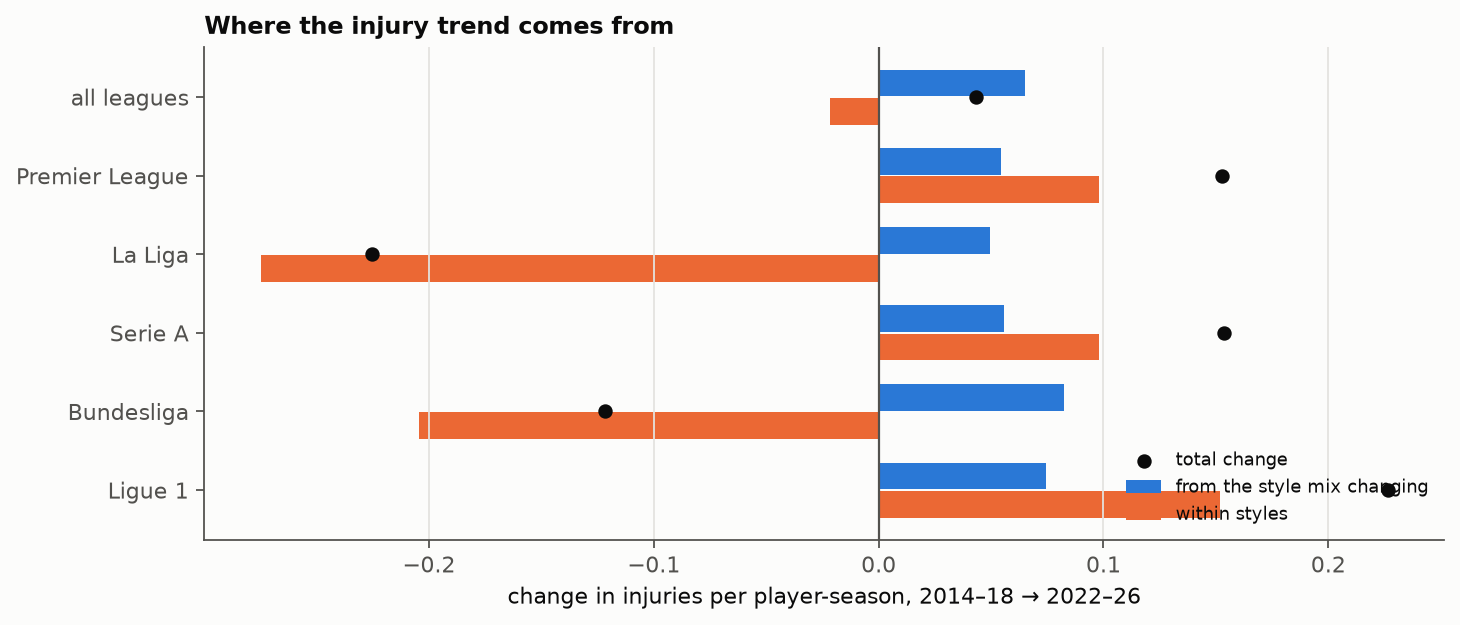

In [22]:
d = decomposition[(decomposition.eras == FIRST_LAST) & (decomposition.outcome == "injuries") & (decomposition.styles == "combined style")].set_index("scope").loc[["all leagues"] + LEAGUES]
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(d))[::-1]
ax.barh(y + 0.18, d["from style mix"], height=0.34, color=SERIES[0], label="from the style mix changing")
ax.barh(y - 0.18, d["within styles"], height=0.34, color=SERIES[1], label="within styles")
ax.scatter(d.change, y, color=INK, zorder=3, s=30, label="total change")
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, d.index)
ax.set_xlabel(f"change in injuries per player-season, {FIRST_LAST}")
ax.set_title("Where the injury trend comes from", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
decomp_fig = save(fig, "05_trend_decomposition.png")

## Step 16. Style dimensions vs injury outcomes across league-seasons

For the 60 league-seasons: average style scores against injury outcomes, **within league** (both centred on the
league's 12-season mean). These level correlations partly repeat shared long-run trends (including recording
changes); the stricter version uses **season-to-season changes** within each league (n = 55). Aggregate association
only.

In [23]:
ls_dims = ts.groupby(["league", "season_key"])[ALL_DIMS].mean()
g = ps.groupby(["league", "season_key"])
known = g.injuries.sum() - g["area: unknown"].sum()
ls_out = pd.DataFrame({
    "injuries / player-season": g.injuries.mean(), "days lost / player-season": g.days_lost.mean(),
    "severe share": g.severe.sum() / g.injuries.sum(), "hamstring share": g["area: hamstring"].sum() / known,
    "knee share": g["area: knee"].sum() / known,
    "muscle share": (g["area: hamstring"].sum() + g["area: unspecified muscle"].sum() + g["area: thigh"].sum()
                     + g["area: calf/achilles/lower leg"].sum()) / known,
})
centred = lambda t: t - t.groupby(level="league").transform("mean")
changes = lambda t: t.groupby(level="league").diff().dropna()
cd, co = centred(ls_dims), centred(ls_out)
dd, do = changes(ls_dims.sort_index()), changes(ls_out.sort_index())
link = pd.DataFrame({o: {d: cd[d].corr(co[o]) for d in ALL_DIMS} for o in co.columns}).round(2)
link_changes = pd.DataFrame({o: {d: dd[d].corr(do[o]) for d in ALL_DIMS} for o in do.columns}).round(2)
strongest = link.abs().stack().sort_values(ascending=False).head(6)
display(link)
display(link_changes)
strongest.rename("|r|").to_frame()

,injuries / player-season,days lost / player-season,severe share,hamstring share,knee share,muscle share
attack_possession,0.09,0.01,-0.02,0.08,-0.32,0.43
attack_patience,0.20,0.13,-0.06,0.05,-0.55,0.64
attack_verticality,-0.06,-0.02,0.03,0.20,0.16,-0.21
attack_directness,-0.20,-0.11,0.08,-0.13,0.51,-0.66
defence_press,-0.09,0.04,0.10,-0.06,0.51,-0.49
defence_high_line,-0.06,-0.02,0.05,0.20,0.18,-0.20
defence_territory_conceded,0.08,0.10,0.07,0.05,-0.04,0.26
defence_aggression,-0.05,0.13,0.16,-0.11,0.39,-0.38


,injuries / player-season,days lost / player-season,severe share,hamstring share,knee share,muscle share
attack_possession,-0.02,0.19,0.22,0.11,0.22,-0.05
attack_patience,0.06,0.00,-0.03,-0.23,-0.13,0.06
attack_verticality,0.11,0.15,0.04,-0.05,0.02,-0.10
attack_directness,-0.09,-0.21,-0.06,-0.04,-0.08,-0.32
defence_press,0.01,0.10,0.01,0.01,0.08,0.01
defence_high_line,0.12,0.14,0.04,-0.05,0.05,-0.14
defence_territory_conceded,0.01,0.31,0.24,0.14,0.35,-0.03
defence_aggression,0.04,0.26,0.13,0.12,0.02,-0.23


|r|
attack_directness muscle share  0.66
attack_patience   muscle share  0.64
                  knee share    0.55
attack_directness knee share    0.51
defence_press     knee share    0.51
                  muscle share  0.49

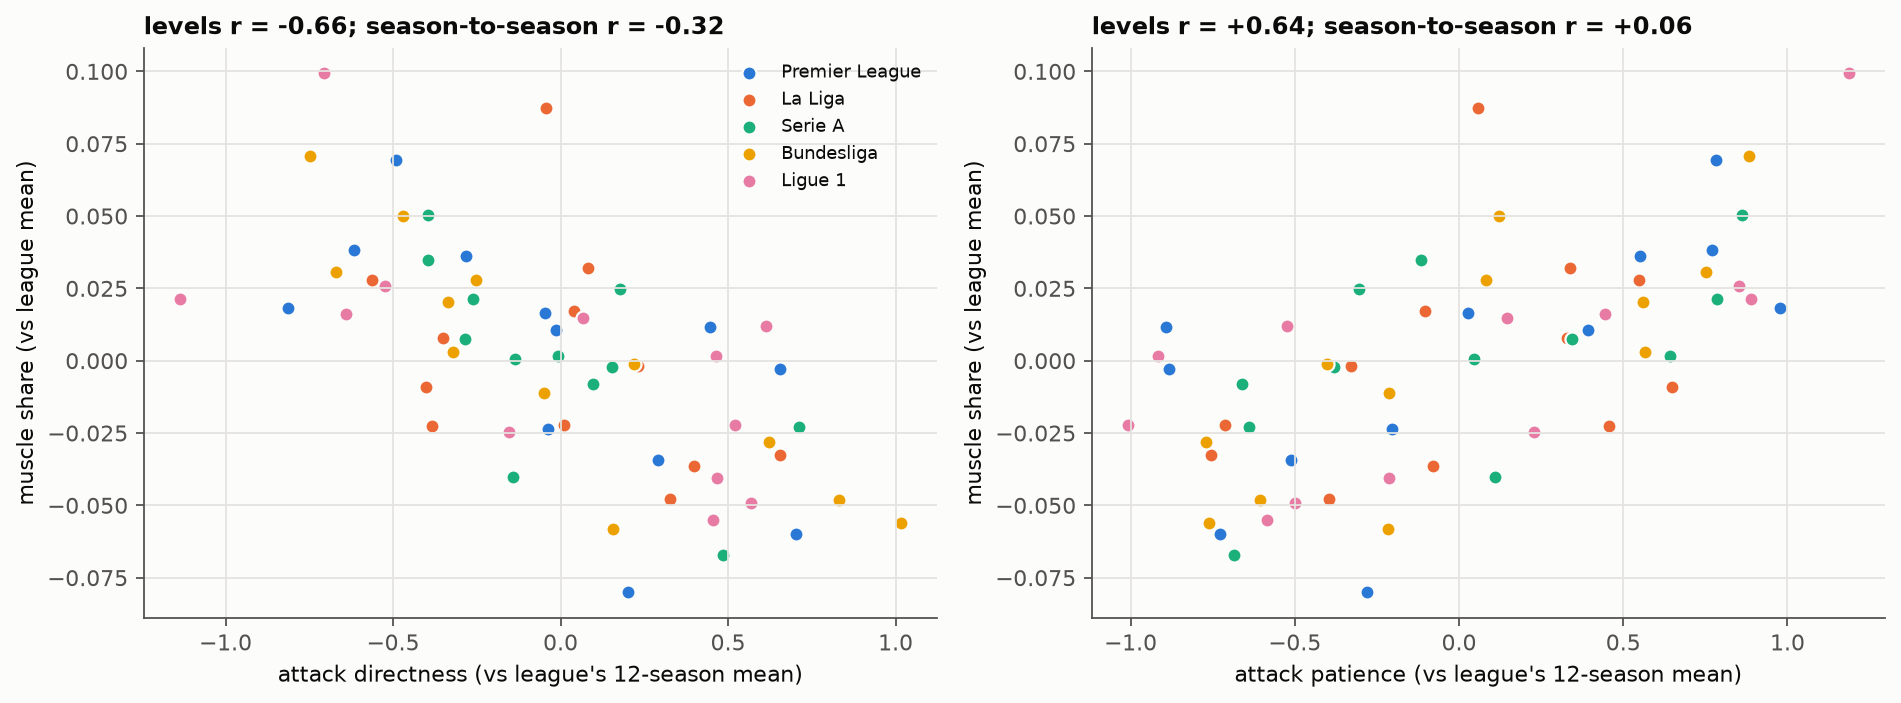

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (d, o) in zip(axes, strongest.index[:2]):
    for lg in LEAGUES:
        ax.scatter(cd.xs(lg, level="league")[d], co.xs(lg, level="league")[o], color=LEAGUE_COLORS[lg], s=40,
                   edgecolors=SURFACE, linewidths=1, label=lg)
    ax.set_xlabel(f"{d.replace('_', ' ')} (vs league's 12-season mean)")
    ax.set_ylabel(f"{o} (vs league mean)")
    ax.set_title(f"levels r = {link.loc[d, o]:+.2f}; season-to-season r = {link_changes.loc[d, o]:+.2f}", loc="left")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
link_fig = save(fig, "05_style_injury_links.png")

## Step 17. One story per league

Each league's evolution in a few sentences from steps 12–15: which attacking and defensive styles grew and shrank,
how the ways of playing changed, and what happened to injuries, split into the style-mix part and the within-style part.

In [25]:
stories = {}
first, last = ERA_ORDER[0], ERA_ORDER[2]
mix_league = {ph: pd.crosstab([clusters.league, clusters.era], clusters[col], normalize="index")[order]
              for ph, col, order in [("attack", "attack_style", ATTACK), ("defence", "defence_style", DEFENCE)]}


def shifts(ph: str, lg: str) -> str:
    m = mix_league[ph].loc[lg]
    ch = (m.loc[last] - m.loc[first]).sort_values()
    up, down = ch.index[-1], ch.index[0]
    return (f"{up} {100 * m.loc[first, up]:.0f}% → {100 * m.loc[last, up]:.0f}%, "
            f"{down} {100 * m.loc[first, down]:.0f}% → {100 * m.loc[last, down]:.0f}%")


for lg in LEAGUES:
    dec = decomposition[(decomposition.scope == lg) & (decomposition.eras == FIRST_LAST) & (decomposition.styles == "combined style")].set_index("outcome")
    inj, days, ham, knee = (dec.loc[o] for o in ["injuries", "days lost", "hamstring injuries", "knee injuries"])
    moved = [f"{d.split('_', 1)[1].replace('_', ' ')} ({d.split('_')[0]}) {shapes.loc[d, lg]}" for d in ALL_DIMS if shapes.loc[d, lg] != "flat"]
    b3 = ts[ts.league == lg].groupby("era").back_three_share.mean()
    stories[lg] = (
        f"**{lg}.** From {first} to {last}: attack {shifts('attack', lg)}; defence {shifts('defence', lg)}; "
        f"back-three minutes {100 * b3[first]:.0f}% → {100 * b3[last]:.0f}%. "
        + (f"Trends: {', '.join(moved)}. " if moved else "")
        + f"Injuries per player-season {inj['from']:.2f} → {inj['to']:.2f} ({inj.change:+.2f}: {inj['from style mix']:+.3f} from the style mix, "
        f"{inj['within styles']:+.3f} within styles); days lost {days['from']:.1f} → {days['to']:.1f}; hamstring injuries "
        f"{ham['from']:.3f} → {ham['to']:.3f} (style mix {ham['from style mix']:+.3f}); knee {knee['from']:.3f} → {knee['to']:.3f} "
        f"(style mix {knee['from style mix']:+.3f})."
    )
    display(Markdown(stories[lg]))

**Premier League.** From 2014–18 to 2022–26: attack Positional possession 10% → 35%, Direct play 36% → 12%; defence Low block 49% → 54%, High press, high line 31% → 25%; back-three minutes 13% → 18%. Trends: possession (attack) rising, patience (attack) rising, verticality (attack) falling, directness (attack) falling, press (defence) falling, high line (defence) falling, territory conceded (defence) rising, aggression (defence) dip. Injuries per player-season 0.56 → 0.71 (+0.15: +0.054 from the style mix, +0.098 within styles); days lost 34.4 → 38.7; hamstring injuries 0.114 → 0.139 (style mix +0.011); knee 0.113 → 0.110 (style mix +0.014).

**La Liga.** From 2014–18 to 2022–26: attack Build-up into the box 18% → 48%, Counter-attack 48% → 16%; defence Compact mid-block 8% → 38%, Aggressive duel press 76% → 39%; back-three minutes 3% → 9%. Trends: possession (attack) rising, patience (attack) rising, verticality (attack) falling, directness (attack) falling, press (defence) falling, high line (defence) falling, territory conceded (defence) dip, aggression (defence) falling. Injuries per player-season 0.71 → 0.49 (-0.23: +0.050 from the style mix, -0.275 within styles); days lost 30.8 → 23.8; hamstring injuries 0.118 → 0.087 (style mix +0.017); knee 0.101 → 0.064 (style mix -0.004).

**Serie A.** From 2014–18 to 2022–26: attack Positional possession 8% → 28%, Direct play 48% → 30%; defence Compact mid-block 12% → 39%, Aggressive duel press 55% → 6%; back-three minutes 29% → 52%. Trends: possession (attack) peak, patience (attack) rising, verticality (attack) falling, directness (attack) falling, press (defence) falling, high line (defence) falling, territory conceded (defence) peak, aggression (defence) falling. Injuries per player-season 0.74 → 0.89 (+0.15: +0.056 from the style mix, +0.098 within styles); days lost 27.1 → 35.0; hamstring injuries 0.083 → 0.133 (style mix +0.014); knee 0.104 → 0.098 (style mix +0.010).

**Bundesliga.** From 2014–18 to 2022–26: attack Build-up into the box 14% → 51%, Direct play 44% → 6%; defence Low block 15% → 61%, Aggressive duel press 39% → 7%; back-three minutes 18% → 46%. Trends: possession (attack) rising, patience (attack) rising, verticality (attack) rising, directness (attack) falling, press (defence) falling, high line (defence) rising, territory conceded (defence) rising, aggression (defence) falling. Injuries per player-season 0.86 → 0.74 (-0.12: +0.082 from the style mix, -0.204 within styles); days lost 42.5 → 35.8; hamstring injuries 0.034 → 0.060 (style mix -0.003); knee 0.151 → 0.111 (style mix +0.005).

**Ligue 1.** From 2014–18 to 2022–26: attack Build-up into the box 12% → 41%, Counter-attack 41% → 9%; defence Low block 10% → 39%, High press, high line 38% → 20%; back-three minutes 5% → 32%. Trends: possession (attack) rising, patience (attack) rising, verticality (attack) falling, directness (attack) falling, press (defence) falling, high line (defence) falling, territory conceded (defence) rising, aggression (defence) falling. Injuries per player-season 0.37 → 0.60 (+0.23: +0.075 from the style mix, +0.152 within styles); days lost 18.4 → 26.2; hamstring injuries 0.059 → 0.079 (style mix +0.008); knee 0.060 → 0.086 (style mix +0.021).

## Step 18. Making results clearer without overfitting

Four standard treatments, fixed in advance and not tuned on the injury outcomes:
- **Shrinkage for small groups (empirical Bayes):** rate ratios of small cells (attack × defence combinations, a style
  within one league) are noisy. Each cell's log RR is pulled towards the average of its family in proportion to its
  uncertainty (bootstrap CI), with the between-cell spread estimated from the data (DerSimonian–Laird). Large,
  precise cells barely move; tiny ones move most.
- **Rolling averages:** 3-season centred rolling means of the season series, next to the raw values, to show the
  trend without the season-to-season noise.
- **Multiple testing (FDR):** each style × body-area pattern is tested within leagues (Cochran–Mantel–Haenszel test,
  stratified by league, with the Mantel–Haenszel odds ratio as effect size), and the p-values are corrected with
  Benjamini–Hochberg; only patterns with q < 0.05 count as findings.
- **Breakdowns:** each style's league-adjusted RR by position and by age band, to see who carries a style's excess.

In [26]:
def shrink(t: pd.DataFrame, rr: str = "RR") -> pd.DataFrame:
    """Empirical-Bayes shrinkage of log rate ratios towards their precision-weighted mean (DerSimonian–Laird)."""
    y = np.log(t[rr])
    se = (np.log(t[f"{rr} high"]) - np.log(t[f"{rr} low"])) / (2 * 1.96)
    w = 1 / se ** 2
    mu = (w * y).sum() / w.sum()
    q = (w * (y - mu) ** 2).sum()
    tau2 = max(0.0, (q - (len(y) - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
    weight = tau2 / (tau2 + se ** 2)
    return pd.DataFrame({f"{rr} raw": t[rr], f"{rr} shrunk": np.exp(mu + weight * (y - mu)), f"{rr} weight on own data": weight})


grid_shrunk = grid[["team-seasons"]].join(shrink(grid)).join(shrink(grid, "days RR"))
within_shrunk = {}
for name in ["attacking style", "defensive style"]:
    col, order = GROUPINGS[name]
    t = summarise(ps, ["league", col])
    within_shrunk[name] = t[["team-seasons"]].join(shrink(t))
display(grid_shrunk.round(2))
for name, t in within_shrunk.items():
    display(t["RR shrunk"].unstack().reindex(index=LEAGUES, columns=GROUPINGS[name][1]).round(2))

team-seasons  RR raw  RR shrunk  RR weight on own data  days RR raw  days RR shrunk  days RR weight on own data
attack_style          defence_style                                                                                                                         
Build-up into the box Aggressive duel press            59    0.98       0.99                   0.90         0.99            1.00                        0.50
                      Compact mid-block               117    1.07       1.07                   0.95         0.99            1.00                        0.65
                      High press, high line            72    1.01       1.01                   0.93         0.96            0.98                        0.60
                      Low block                       107    0.96       0.96                   0.97         1.04            1.03                        0.64
Counter-attack        Aggressive duel press            91    0.88       0.90                   0.91         0.96            0.98                        0.53
                      Compact mid-block                49    0.84       0.88                   0.79         0.90            0.97                        0.30
                      High press, high line            25    1.04       1.04                   0.74         1.07            1.03                        0.31
                      Low block                       114    0.90       0.91                   0.95         0.96            0.98                        0.62
Direct play           Aggressive duel press           129    0.91       0.92                   0.94         1.00            1.00                        0.64
                      Compact mid-block                66    0.95       0.96                   0.88         0.95            0.98                        0.47
                      High press, high line            44    1.08       1.07                   0.85         1.01            1.01                        0.45
                      Low block                       123    0.95       0.96                   0.94         0.98            0.99                        0.68
Positional possession Aggressive duel press             7    1.44       1.42                   0.95         1.58            1.11                        0.22
                      Compact mid-block                57    1.16       1.15                   0.94         1.01            1.01                        0.46
                      High press, high line           104    1.28       1.27                   0.95         1.09            1.06                        0.72
                      Low block                         6    1.18       1.14                   0.72         1.16            1.03                        0.16

attack_style,Positional possession,Build-up into the box,Counter-attack,Direct play
league,,,,
Premier League,1.23,0.95,0.93,0.94
La Liga,1.50,1.01,0.91,0.91
Serie A,1.08,0.98,0.98,1.00
Bundesliga,1.08,1.01,0.95,1.01
Ligue 1,1.37,1.16,0.79,0.92


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
league,,,,
Premier League,1.13,1.03,1.04,0.91
La Liga,1.31,1.09,0.91,0.79
Serie A,0.97,1.07,0.95,1.02
Bundesliga,1.05,1.04,0.98,0.96
Ligue 1,1.17,0.90,0.98,1.01


In [27]:
ROLL = 3
trend = by_season[["injuries / player-season", "days lost / player-season"]].join(unknown_share)
trend_rolling = trend.rolling(ROLL, center=True, min_periods=2).mean().add_suffix(f" ({ROLL}-season mean)")
league_rolling = season_league.rolling(ROLL, center=True, min_periods=2).mean()
display(trend.join(trend_rolling).round(3))
league_rolling.round(3)

,injuries / player-season,days lost / player-season,unknown body area,injuries / player-season (3-season mean),days lost / player-season (3-season mean),unknown body area (3-season mean)
season_key,,,,,,
2014-15,0.592,29.080,0.157,0.601,29.317,0.147
2015-16,0.610,29.553,0.137,0.636,30.694,0.139
2016-17,0.707,33.448,0.123,0.663,30.853,0.120
2017-18,0.672,29.557,0.099,0.720,31.989,0.120
2018-19,0.781,32.963,0.138,0.722,31.481,0.111
2019-20,0.714,31.924,0.096,0.717,30.395,0.130
2020-21,0.655,26.298,0.156,0.654,27.985,0.132
2021-22,0.594,25.734,0.145,0.621,26.708,0.148
2022-23,0.614,28.093,0.142,0.622,28.763,0.142


league,Premier League,La Liga,Serie A,Bundesliga,Ligue 1
season_key,,,,,
2014-15,0.553,0.585,0.735,0.816,0.338
2015-16,0.557,0.687,0.736,0.844,0.380
2016-17,0.546,0.773,0.757,0.870,0.392
2017-18,0.736,0.820,0.756,0.907,0.398
2018-19,0.848,0.749,0.781,0.862,0.373
2019-20,0.884,0.655,0.820,0.802,0.416
2020-21,0.692,0.547,0.849,0.725,0.444
2021-22,0.577,0.457,0.868,0.694,0.502
2022-23,0.591,0.467,0.855,0.681,0.506


In [28]:
def cmh(data: pd.DataFrame, col: str, style: str, area: str) -> tuple[float, float]:
    """Cochran–Mantel–Haenszel test of 'injury in this area' vs 'this style' stratified by league: (MH odds ratio, p)."""
    num = den = a_sum = e_sum = var = 0.0
    for _, d in data.groupby("league"):
        known = d.injuries - d["area: unknown"]
        a = d.loc[d[col] == style, f"area: {area}"].sum()
        b = known[d[col] == style].sum() - a
        c = d.loc[d[col] != style, f"area: {area}"].sum()
        dd = known[d[col] != style].sum() - c
        n = a + b + c + dd
        if n < 2:
            continue
        num += a * dd / n
        den += b * c / n
        a_sum += a
        e_sum += (a + b) * (a + c) / n
        var += (a + b) * (c + dd) * (a + c) * (b + dd) / (n ** 2 * (n - 1))
    stat = (abs(a_sum - e_sum) - 0.5) ** 2 / var
    return num / den, chi2.sf(stat, 1)


def benjamini_hochberg(p: pd.Series) -> pd.Series:
    order = p.sort_values()
    q = (order * len(p) / np.arange(1, len(p) + 1)).iloc[::-1].cummin().iloc[::-1].clip(upper=1)
    return q.reindex(p.index)


fdr_rows = []
for name in ["attacking style", "defensive style", "formation"]:
    col, order = GROUPINGS[name]
    for style in order:
        for area in AREAS:
            odds, p = cmh(ps, col, style, area)
            fdr_rows.append({"grouping": name, "style": style, "area": area, "MH odds ratio": odds, "p": p,
                             "leagues above 1": int(body[name]["above"].loc[style, area])})
body_fdr = pd.DataFrame(fdr_rows)
body_fdr["q (BH)"] = benjamini_hochberg(body_fdr.p)
body_fdr["finding"] = body_fdr["q (BH)"] < 0.05
body_findings = body_fdr[body_fdr.finding].sort_values(["grouping", "MH odds ratio"], ascending=[True, False])
print(f"{body_fdr.finding.sum()} of {len(body_fdr)} style × body-area patterns survive FDR (q < 0.05)")
body_findings.round(4)

9 of 80 style × body-area patterns survive FDR (q < 0.05)


,grouping,style,area,MH odds ratio,p,leagues above 1,q (BH),finding
0,attacking style,Positional possession,unspecified muscle,1.2061,0.0000,3,0.0009,True
17,attacking style,Counter-attack,knee,1.1339,0.0046,5,0.0410,True
16,attacking style,Counter-attack,unspecified muscle,0.8720,0.0017,1,0.0170,True
1,attacking style,Positional possession,knee,0.8180,0.0000,0,0.0009,True
49,defensive style,Aggressive duel press,knee,1.2336,0.0000,4,0.0005,True
33,defensive style,"High press, high line",knee,0.8547,0.0004,0,0.0060,True
58,defensive style,Low block,hamstring,0.8521,0.0006,1,0.0068,True
48,defensive style,Aggressive duel press,unspecified muscle,0.8425,0.0000,1,0.0009,True
59,defensive style,Low block,groin/adductor/hip,0.8081,0.0001,2,0.0009,True


In [29]:
breakdown_rows = []
for name in ["attacking style", "defensive style"]:
    col, order = GROUPINGS[name]
    for by in ["position", "age_band"]:
        t = summarise(ps.dropna(subset=[by]), [col, by])
        for (style, group), r in t.iterrows():
            breakdown_rows.append({"grouping": name, "style": style, "by": by, "group": str(group), "player-seasons": r["player-seasons"],
                                   "injuries / player-season": r["injuries / player-season"], "RR": r["RR"],
                                   "RR low": r["RR low"], "RR high": r["RR high"], "excess / 100 player-seasons": r["excess / 100 player-seasons"]})
breakdown = pd.DataFrame(breakdown_rows)
for name in ["attacking style", "defensive style"]:
    for by in ["position", "age_band"]:
        display(breakdown[(breakdown.grouping == name) & (breakdown.by == by)].pivot(index="style", columns="group", values="RR")
                .reindex(GROUPINGS[name][1]).round(2))

group,Defender,Forward,Goalkeeper,Midfielder
style,,,,
Positional possession,1.41,1.25,0.73,1.21
Build-up into the box,1.13,0.98,0.62,0.99
Counter-attack,0.98,0.90,0.58,0.89
Direct play,1.07,0.95,0.58,0.93


group,22–25,26–29,30+,≤21
style,,,,
Positional possession,1.20,1.47,1.53,0.62
Build-up into the box,0.92,1.19,1.24,0.54
Counter-attack,0.85,0.99,1.03,0.54
Direct play,0.90,1.06,1.14,0.53


group,Defender,Forward,Goalkeeper,Midfielder
style,,,,
"High press, high line",1.25,1.11,0.72,1.18
Compact mid-block,1.16,1.03,0.63,0.99
Aggressive duel press,1.08,0.87,0.59,0.92
Low block,1.04,0.99,0.57,0.90


group,22–25,26–29,30+,≤21
style,,,,
"High press, high line",1.11,1.31,1.43,0.61
Compact mid-block,0.97,1.22,1.27,0.49
Aggressive duel press,0.84,1.07,1.11,0.54
Low block,0.88,1.05,1.10,0.57


## Step 19. Report

In [30]:
ps.to_parquet(OUT_DIR / "player_seasons.parquet", index=False)
# Result tables, for the Phase 6 dashboard.
TABLES = OUT_DIR / "tables"
TABLES.mkdir(exist_ok=True)
for name, t in results.items():
    t.to_csv(TABLES / f"rates_{name.replace(' ', '_')}.csv")
grid.to_csv(TABLES / "attack_defence_grid.csv")
for name, b in body.items():
    b["median"].to_csv(TABLES / f"body_median_{name.replace(' ', '_')}.csv")
    b["above"].to_csv(TABLES / f"body_above_{name.replace(' ', '_')}.csv")
by_season.join(unknown_share).to_csv(TABLES / "by_season.csv")
decomposition.to_csv(TABLES / "decomposition.csv", index=False)
pd.Series(stories, name="story").rename_axis("league").to_csv(TABLES / "league_stories.csv")
for ph, c in cards.items():
    c.to_csv(TABLES / f"cards_{ph}.csv")
grid_shrunk.to_csv(TABLES / "attack_defence_grid_shrunk.csv")
for name, t in within_shrunk.items():
    t.to_csv(TABLES / f"within_league_shrunk_{name.replace(' ', '_')}.csv")
trend.join(trend_rolling).to_csv(TABLES / "season_trend_rolling.csv")
league_rolling.to_csv(TABLES / "season_league_rolling.csv")
body_fdr.to_csv(TABLES / "body_areas_fdr.csv", index=False)
breakdown.to_csv(TABLES / "breakdown_position_age.csv", index=False)


def sig_list(t: pd.DataFrame, rr: str = "RR") -> str:
    lo, hi = f"{rr} low", f"{rr} high"
    s = t[(t[lo] > 1) | (t[hi] < 1)]
    return ", ".join(f"{i} {r:.2f}" for i, r in s[rr].items()) or "none"


text = ["# Phase 5: Injury analysis", "",
        f"Generated {date.today().isoformat()} by `notebooks/05_injury_analysis.ipynb`, where each step is shown with its checks.", "",
        "## Key numbers", "",
        f"- {len(ps):,} player-club-seasons, {int(ps.injuries.sum()):,} injuries > 7 days, {int(ps.days_lost.sum()):,} days lost."]
for name in ["attacking style", "defensive style", "formation"]:
    text.append(f"- {name.capitalize()}: injury RR CI excludes 1 for {sig_list(results[name])}; days RR for {sig_list(results[name], 'days RR')}; "
                f"robust in every sensitivity check: {', '.join(robust[name]) or 'none'}.")
text += ["", "## 1. Injuries by style", ""]
for name in GROUPINGS:
    text += [f"### {name.capitalize()}", "", md_table(fmt(results[name])[COLS].rename_axis(name)), ""]
text += ["Injury RR, attacking style (rows) × defensive style (columns):", "", md_table(grid_rr.round(2).rename_axis("attack \\ defence")), "",
         "Days lost RR:", "", md_table(grid_days.round(2).rename_axis("attack \\ defence")), "",
         f"![Rates](figures/{style_fig})", "", f"![Grid](figures/{grid_fig})", "",
         "## 2. Body areas by style (relative to the league's share; median over leagues, leagues above 1)", ""]
for name in ["attacking style", "defensive style", "formation"]:
    b = body[name]
    text += [f"### {name.capitalize()} (pooled chi² p = {b['p']:.2g}, Cramér's V = {b['V']:.3f})", "",
             md_table(b["median"].round(2).rename_axis(name)), "", md_table(b["above"].rename_axis(name)), ""]
text += [f"![Body areas](figures/{area_fig})", "", "## 3. Seasons", "",
         md_table(fmt(by_season)[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]].join(unknown_share.round(3)).rename_axis("season")), "",
         f"![Trend](figures/{trend_fig})", "", f"![Shares](figures/{shares_fig})", "", "## 4. Leagues", "",
         md_table(fmt(by_league)[COLS].rename_axis("league")), ""]
for name, (rr, n) in within.items():
    text += [f"{name.capitalize()} RR within each league:", "", md_table(rr.round(2).rename_axis("league")), ""]
text += [f"![Within league](figures/{league_fig})", "", "## 5. Age and position", ""]
for name, t in adjusted.items():
    text += [md_table(t.rename_axis(name)), ""]
text += ["## 6. Team strength and workload", ""]
for name in strength_rr:
    text += [f"{name.capitalize()} RR within strength thirds:", "", md_table(strength_rr[name].round(2).rename_axis("strength")), "",
             f"{name.capitalize()} RR within congestion thirds:", "", md_table(congestion_rr[name].round(2).rename_axis("congestion")), ""]
text += ["By congestion:", "", md_table(fmt(by_congestion)[COLS].rename_axis("congestion")), "",
         "## 7. Fitness absences (Bundesliga, secondary outcome)", ""]
for name, f in fitness.items():
    text += [md_table(f.rename_axis(name)), ""]
text += ["## 8. Sensitivity checks (injury RR)", ""]
for name, t in sensitivity.items():
    text += [f"### {name.capitalize()}", "", md_table(t.rename_axis("variant")), ""]
text += ["## 9. Style cards (core team-seasons)", ""]
for ph, title in [("attack", "Attacking styles"), ("defence", "Defensive styles")]:
    text += [f"### {title}", ""]
    for name, c in cards[ph].iterrows():
        text.append(f"- **{name}** ({c['team-seasons']} team-seasons, core {c['core']}): {c['how it plays']}. {c['in numbers (core)']}. "
                    f"Back-three minutes {c['back-three minutes']}; points/match {c['points/match']}; most often with {c['most often with']}. "
                    f"Typical: {c['typical 2014–18']} | {c['typical 2018–22']} | {c['typical 2022–26']}.")
    text.append("")
text += ["Injury RR, all teams vs core teams only:", ""]
for name, t in core_check.items():
    text += [md_table(t.rename_axis(name)), ""]
text += ["## 10. How the ways of attacking and defending changed", "",
         md_table(era_all.T.round(2).assign(shape=shapes["all leagues"]).rename_axis("dimension (z)")), "",
         md_table(shapes.rename_axis("dimension")), "", md_table(raw_by_era.round(3).rename_axis("measure (all leagues)")), "",
         f"![Dimensions](figures/{dims_fig})", "", "## 11. How teams move between styles", ""]
for ph, tr in transitions.items():
    text += [f"{ph.title()}: style kept from one season to the next {tr['kept']:.0%}.", "",
             md_table((100 * tr["share"]).round(0).rename_axis(f"{ph} \u2192 next season")), "", md_table(tr["flows"], index=False), ""]
text += ["## 12. Style mix and injuries per era", ""]
for name in mix_era:
    text += [f"### {name.capitalize()}", "", md_table((100 * mix_era[name]).round(1).rename_axis("era")), "",
             "Injury RR per era (fixed league baselines):", "", md_table(rr_era[name].round(2).rename_axis("era")), ""]
text += ["## 13. Where the injury trend comes from (Kitagawa decomposition)", "",
         md_table(main_dec.drop(columns=["scope", "styles"]).round(3), index=False), "",
         f"Style-mix part, {FIRST_LAST}, by which phase's styles are used:", "", md_table(phase_dec.round(3).rename_axis("outcome")), "",
         f"![Decomposition](figures/{decomp_fig})", "",
         "## 14. Style dimensions vs injury outcomes (60 league-seasons, within league)", "",
         "Levels:", "", md_table(link.rename_axis("dimension")), "",
         "Season-to-season changes (n = 55):", "", md_table(link_changes.rename_axis("dimension")), "",
         f"![Links](figures/{link_fig})", "", "## 15. One story per league", "", *[f"{s}\n" for s in stories.values()], "",
         "## 16. Clearer results (fixed in advance, not tuned on outcomes)", "",
         "### Shrinkage of small cells (empirical Bayes)", "",
         "Attack × defence grid, raw vs shrunk injury RR (weight on own data: 1 = kept as is, 0 = fully pulled to the average):", "",
         md_table(grid_shrunk[["team-seasons", "RR raw", "RR shrunk", "RR weight on own data"]].round(2).rename_axis(["attack", "defence"])), "",
         *[x for name, t in within_shrunk.items() for x in (f"{name.capitalize()} RR within each league, shrunk:", "",
           md_table(t["RR shrunk"].unstack().reindex(index=LEAGUES, columns=GROUPINGS[name][1]).round(2).rename_axis("league")), "")],
         "### 3-season rolling averages", "", md_table(trend.join(trend_rolling).round(3).rename_axis("season")), "",
         f"### Body-area patterns surviving false-discovery-rate correction ({int(body_fdr.finding.sum())} of {len(body_fdr)}; "
         "Cochran–Mantel–Haenszel test within leagues, Benjamini–Hochberg q < 0.05)", "",
         md_table(body_findings[["grouping", "style", "area", "MH odds ratio", "q (BH)", "leagues above 1"]].round(4), index=False), "",
         "### Who carries a style's excess: RR by position and age band", "",
         *[x for name in ["attacking style", "defensive style"] for by in ["position", "age_band"] for x in (
           f"{name.capitalize()} × {by.replace('_', ' ')}:", "",
           md_table(breakdown[(breakdown.grouping == name) & (breakdown.by == by)].pivot(index="style", columns="group", values="RR")
                    .reindex(GROUPINGS[name][1]).round(2).rename_axis(name)), "")],
         "## 17. Outputs", "",
         f"- `data/{PHASE}/player_seasons.parquet`: the player-club-season table with styles, formation, strength, workload, age, position and injuries.", ""]
(REPORTS_DIR / "05_injury_analysis.md").write_text("\n".join(text), encoding="utf-8")
print("wrote", REPORTS_DIR / "05_injury_analysis.md")

wrote /Users/mohammadshweiki/Downloads/coding-projects/football-injuries/reports/05_injury_analysis.md
